In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import pathlib
import re
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = next(p for p in (pathlib.Path().resolve(), *pathlib.Path().resolve().parents) if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import const
import domain
import dose
import json_util
import pde_residual
import pinn_training
import plot_util
import three_net
import comsol_case

plot_util.apply_plot_style()

RESULT = ROOT / "result" / "cfd_invert_property"
RESULT.mkdir(parents=True, exist_ok=True)
FIGURE = RESULT / "figure"
FIGURE.mkdir(exist_ok=True)

RESUME_TRAINING = "auto"
FORCE_TRAIN = False
ADAM_EPOCHS = const.ADAM_EPOCHS
LBFGS_ITERATIONS = const.CFD_LBFGS_ITERATIONS
WEIGHTS = {}

DATA_DIR = ROOT / "data" / "comsol" / const.CFD_CASE
FLOW_FIELDS = const.CFD_PULSE_FLOW_FIELDS
CNET_FIELDS = ("c",)


def net_of(name):
    return "purge" if name.startswith("purge") else ("flow" if "flow" in name else "cnet")


def diag_units(rec):
    scales = rec["scales"]
    units = {"c": ("c [mol/m^3]", scales["C"])}
    if "U" in scales:
        units.update({"u": ("u [m/s]", scales["U"]), "v": ("v [m/s]", scales["U"]),
                      "w": ("w [m/s]", scales["U"]), "p": ("p - Pout [Pa]", scales["P"])})
    return units


def history_dim(rec):
    return {**rec["history"], **{k: np.asarray(rec["history"][k]) * rec["param_scale"][k] for k in rec["params"]}}


PROVIDERS = {}


def get_provider(case, name):
    if case not in PROVIDERS:
        model, state = pinn_training.PINNTraining.load_checkpoint(RESULT / f"{case}.pt", feature=FEATURE)
        assert state["train_state"]["lbfgs_done"], f"{case}: frozen velocity source is not fully trained"
        PROVIDERS[case] = three_net.FrozenVelocity(model, name=name)
    return PROVIDERS[case]


def make_trainer(name, seg, known, ckpt, resume):
    case = CASES[name]
    dom = domain.MeshDomain(mesh, L, seg["t_range"], s_values=seg.get("s_values"),
                            s_discrete=case.get("s_discrete", False))
    common = dict(domain=dom, boundary=seg["boundary"], group=seg["dataset"]["node"],
                  hidden=seg.get("hidden", const.HIDDEN_LAYERS), num_node=seg.get("num_node"),
                  sigma=seg["sigma"], weights=WEIGHTS, adam_epochs=ADAM_EPOCHS, lbfgs_iterations=LBFGS_ITERATIONS,
                  seed=case.get("seed", const.SEED), feature=FEATURE, checkpoint_path=ckpt, resume=resume)
    dataset = {k: seg["dataset"][k] for k in ("X", *seg["fields"], "node", "time_index")}
    if case["net"] == "cnet":
        provider = get_provider(case["frozen"], seg["provider_name"])
        return three_net.CNetTraining(dataset, fields=seg["fields"], pde=[three_net.make_species(provider)],
                                      inverse={}, known=known, provider=provider, **common)
    return pinn_training.PINNTraining(dataset, fields=seg["fields"], pde=seg["pde"], inverse=case["inverse"],
                                      known=known, **common)


def train_case(name):
    case = CASES[name]
    seg = SEGMENT[case["segment"]]
    ckpt, path = RESULT / f"{name}.pt", RESULT / f"{name}.json"
    if FORCE_TRAIN:
        ckpt.unlink(missing_ok=True)
    known = dict(case["known"])
    for key, src in case.get("known_from", {}).items():
        dim = json_util.load_json(RESULT / f"{src}.json")["estimate_dim"][key]["value"]
        known[key] = dim / seg["param_scale"][key]
    trainer = make_trainer(name, seg, known, ckpt, False if FORCE_TRAIN else RESUME_TRAINING)
    if FORCE_TRAIN or not (trainer.lbfgs_done and path.exists()):
        res = trainer.train()
        params = res["params"]
        rec = {"case": name, "segment": case["segment"], "net": case["net"], "params": params,
               **({"cycles": [int(c) for c in seg["cycles"]], "s_values": [float(v) for v in seg["s_values"]]}
                  if seg.get("s_values") is not None else {}),
               "params_dim": {k: v * seg["param_scale"][k] for k, v in params.items()},
               "estimate": res["estimate"],
               "estimate_dim": pinn_training.PINNTraining.scale_estimate(res["estimate"], seg["param_scale"]),
               "true": {k: seg["true"][k] for k in params}, "true_dim": seg["true_dim"],
               "known_dim": {k: v * seg["param_scale"][k] for k, v in known.items() if k in seg["param_scale"]},
               "param_scale": seg["param_scale"], "scales": seg["scales"], "window": seg["window"],
               "sigma": seg["sigma"],
               "split": {"train": int(trainer.train_data["X"].shape[0]), "valid": int(trainer.valid_data["X"].shape[0]),
                         "test": int(trainer.test_data["X"].shape[0])},
               "n_colloc": res["config"]["n_colloc"], "n_boundary": res["config"]["n_boundary"],
               "residual": {s: pinn_training.PINNTraining.residual_stats(trainer.evaluate_residual(s)) for s in const.SPLITS},
               "history": res["history"], "best": res["best"],
               "test": trainer.diag_record("test"),
               "loss": res["loss"], "terms": res["terms"], "lbfgs": res["lbfgs"], "wall_seconds": res["wall_seconds"],
               "config": res["config"]}
        json_util.save_json(path, rec)
    rec = json_util.load_json(path)
    stop = rec.get("lbfgs") or {}
    print(f"[{name}] split: {rec['split']}   wall: {rec['wall_seconds'] / 60:.1f} min   final loss: {rec['loss']:.3e}   "
          f"best: epoch {pinn_training.PINNTraining.best_axis(rec['best'])} ({rec['best']['phase']})   "
          f"L-BFGS: {stop.get('n_iter')} iterations, {stop.get('reason')}"
          + (f"   WARNING: {'/'.join(stop['pinned'])} on a search bound" if stop.get("pinned") else ""))
    for k, v in rec["estimate_dim"].items():
        true = rec["true_dim"][k]
        print(f"  {k}: true = {true:.4e}   recovered = {v['value']:.4e} +- {v['sem']:.1e}   "
              f"rel_error = {v['value'] / true - 1:+.2%}   "
              f"(p16-p84 {v['p16'] / true - 1:+.2%} .. {v['p84'] / true - 1:+.2%}, "
              f"best-val model {rec['params_dim'][k] / true - 1:+.2%})")
        if abs(v["drift"]) > const.LBFGS_DRIFT_SIGMA * v["sem"]:
            print(f"    WARNING: still drifting by {100 * v['drift'] / true:+.2f} pp across the tail window "
                  f"(sem {100 * v['sem'] / true:.2f} pp): the budget is too short, this is not a settled value")
    for k, v in rec["known_dim"].items():
        print(f"  {k}: known = {v:.4e} ({v / rec['true_dim'][k] - 1:+.2%} vs true), not inverted here")
    return rec


print("device:", "cuda " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

device: cuda NVIDIA GeForce RTX 5090


# CFD Case and Three Networks

In [3]:
meta, mesh, field_paths = comsol_case.load_case(DATA_DIR)
SEG_LABEL = comsol_case.segment_labels(meta)
FIELD_DATA = all(pathlib.Path(p).exists() for p in field_paths.values())
spatial = np.load(field_paths[const.CFD_PULSE_LABEL])["spatial"] if FIELD_DATA else None
V = np.asarray(mesh["vertices"], float)
L = float(np.abs(V[:, 0]).max())
c_bot = meta["parameters"]["c_bot"]["value"]
Pout = meta["parameters"]["Pout"]["value"]
rho = float(np.load(field_paths[const.CFD_PULSE_LABEL])["rho"]) if FIELD_DATA else float("nan")
BOUNDS_DIM = {"mu": const.CFD_MU_BOUNDS, "D": const.CFD_D_BOUNDS}
INIT_DIM = {"mu": const.CFD_MU_INIT, "D": const.CFD_D_INIT}

PERM = comsol_case.match_nodes(mesh["vertices"], spatial) if FIELD_DATA else None

GEODESIC = comsol_case.geodesic_from_faces(mesh, comsol_case.faces_of(meta, "spf", "inlet"))
IN_TUBE = GEODESIC < const.CFD_TUBE_G_CUT
FEATURE = domain.NodeFeature(mesh["vertices"], IN_TUBE.astype(float), L, name="inlet_tube")

print(f"mesh: {V.shape[0]} nodes, L = {L:.4f} m; c_bot = {c_bot} mol/m^3, Pout = {Pout} Pa, rho = {rho} kg/m^3")
print(f"tube label: {IN_TUBE.sum()} of {IN_TUBE.size} mesh nodes are inside the inlet tube")
print(f"segments in the case: {len(SEG_LABEL)} ({sum(k == 'pulse' for k, _ in SEG_LABEL)} pulse, "
      f"{sum(k == 'purge' for k, _ in SEG_LABEL)} purge)")
for key in ("mu", "D"):
    print(f"{key}: init = {INIT_DIM[key]:.1e}, bounds = {BOUNDS_DIM[key]} (log)")

if not FIELD_DATA:
    print("\nCFD field snapshots are not part of this package: the data-building and training cells\n"
          "are skipped, and the plotting cells replay from the stored JSON in result/.")

mesh: 19874 nodes, L = 0.0635 m; c_bot = 0.00739 mol/m^3, Pout = 4090.0 Pa, rho = 0.056444000000000015 kg/m^3
tube label: 3875 of 19874 mesh nodes are inside the inlet tube
segments in the case: 19 (10 pulse, 9 purge)
mu: init = 1.0e-05, bounds = (1e-06, 0.0001) (log)
D: init = 3.0e-05, bounds = (1e-06, 0.001) (log)


In [4]:
def symmetry(X, c):
    return pde_residual.grad(c, X)[:, 1:2]


def wall_noflux(X, c, normal):
    return (pde_residual.grad(c, X)[:, :3] * normal).sum(dim=1, keepdim=True)


def bottom(c):
    return c - 1.0


def inlet(c):
    return c


def outlet(X, c, normal):
    return (pde_residual.grad(c, X)[:, :3] * normal).sum(dim=1, keepdim=True)


def initial(node, c, snapshot):
    return c - snapshot[node]


def cnet_boundary_specs(meta):
    faces = lambda role: comsol_case.faces_of(meta, "tds", role)
    num = const.CFD_PURGE_NUM_BOUNDARY
    return [{"name": "symmetry", "faces": faces("symmetry"), "residual": symmetry, "num": num["symmetry"]},
            {"name": "wall_noflux", "faces": faces("no_flux"), "residual": wall_noflux, "num": num["wall_noflux"]},
            {"name": "bottom", "faces": faces("concentration"), "residual": bottom, "num": num["bottom"]},
            {"name": "inlet", "faces": faces("inlet"), "residual": inlet, "num": num["inlet"]},
            {"name": "outlet", "faces": faces("outlet"), "residual": outlet, "num": num["outlet"]},
            {"name": "initial", "axis": 3, "side": "lo", "residual": initial, "num": num["initial"]}]


CNET_BOUNDARY = cnet_boundary_specs(meta)


def flow_symmetry_noc(X, u, v, w, p):
    return {"v": v, "dn": torch.cat([pde_residual.grad(f, X)[:, 1:2] for f in (u, w, p)], dim=1)}


def flow_wall_noslip(u, v, w):
    return torch.cat([u, v, w], dim=1)


def flow_inlet_noc(u, v):
    return {"tangential": torch.cat([u, v], dim=1)}


def flow_outlet_noc(u, v, p):
    return {"p": p, "tangential": torch.cat([u, v], dim=1)}


def flow_initial_noc(node, u, v, w, p, snapshot):
    return torch.cat([u, v, w, p], dim=1) - snapshot[node]


def flow_boundary_specs(meta):
    faces = lambda physics, role: comsol_case.faces_of(meta, physics, role)
    num = const.CFD_PULSE_NUM_BOUNDARY
    return [{"name": "symmetry", "faces": faces("tds", "symmetry"), "residual": flow_symmetry_noc, "num": num["symmetry"]},
            {"name": "wall_noslip", "faces": faces("spf", "wall"), "residual": flow_wall_noslip, "num": num["wall_noslip"]},
            {"name": "inlet", "faces": faces("spf", "inlet"), "residual": flow_inlet_noc, "num": num["inlet"]},
            {"name": "outlet", "faces": faces("spf", "outlet"), "residual": flow_outlet_noc, "num": num["outlet"]},
            {"name": "initial", "axis": 3, "side": "lo", "residual": flow_initial_noc, "num": num["initial"]}]


FLOW_BOUNDARY = flow_boundary_specs(meta)


def rebuild_boundary(base, snapshot, num=None):
    return [{**spec, "table": {"snapshot": snapshot}, **({} if num is None else {"num": num})}
            if spec["name"] == "initial" else spec for spec in base]


def swap_initial(base, fn):
    return [{**{k: v for k, v in spec.items() if k != "table"}, "residual": fn}
            if spec["name"] == "initial" else spec for spec in base]


def initial(node, segment, c, snapshot):
    return c - snapshot[segment, node]


MERGED_PURGE_BOUNDARY = swap_initial(CNET_BOUNDARY, initial)


def merged_cnet_boundary(base):
    def initial(node, segment, c, snapshot):
        return c - snapshot[segment, node]
    return swap_initial(base, initial)


def merged_flow_boundary(base):
    def flow_initial_noc(node, segment, u, v, w, p, snapshot):
        return torch.cat([u, v, w, p], dim=1) - snapshot[segment, node]
    return swap_initial(base, flow_initial_noc)


MERGED_CNET_BOUNDARY = merged_cnet_boundary(CNET_BOUNDARY)
MERGED_FLOW_BOUNDARY = merged_flow_boundary(FLOW_BOUNDARY)

for label, base in (("c path (purge c-PINN / pulse c-net)", CNET_BOUNDARY), ("flow net", FLOW_BOUNDARY)):
    print(f"{label:<38}" + str({b["name"]: b.get("faces", "t = t_lo (mesh nodes)") for b in base}))
print("residual names in the fingerprint: "
      + ", ".join(f"{b['name']}={b['residual'].__qualname__}" for b in MERGED_CNET_BOUNDARY))

c path (purge c-PINN / pulse c-net)   {'symmetry': (2,), 'wall_noflux': (1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 24), 'bottom': (3,), 'inlet': (14,), 'outlet': (23,), 'initial': 't = t_lo (mesh nodes)'}
flow net                              {'symmetry': (2,), 'wall_noslip': (1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 24), 'inlet': (14,), 'outlet': (23,), 'initial': 't = t_lo (mesh nodes)'}
residual names in the fingerprint: symmetry=symmetry, wall_noflux=wall_noflux, bottom=bottom, inlet=inlet, outlet=outlet, initial=merged_cnet_boundary.<locals>.initial


In [5]:
def build_segment(kind, index, scales=None, n_data=None):
    field = np.load(field_paths[SEG_LABEL[(kind, index)]])
    assert np.array_equal(field["spatial"], spatial), f"{kind} {index}: node order differs from the first cycle"
    times, vel, conc = field["times"], field["vel_data"], field["conc_data"][..., 0]
    t0 = float(times[0])
    duty = comsol_case.pulse_waveform(times, meta["pulse_schedule"])
    if kind == "pulse":
        rel = times - t0
        win = np.flatnonzero((duty >= 1 - 1e-12) & (rel >= const.CFD_T_WINDOW[0] - 1e-9)
                             & (rel <= const.CFD_T_WINDOW[1] + 1e-9))
        assert win.size > 0 and np.all(np.diff(win) == 1)
        if scales is None:
            u_scale = float(np.linalg.norm(vel[..., 1:], axis=-1)[:, win].max())
            scales = {"L": L, "U": u_scale, "tau": L / u_scale, "P": rho * u_scale ** 2, "C": c_bot,
                      "Pout": Pout, "rho": rho}
        t_range = (float(rel[win[0]]) / scales["tau"], float(rel[win[-1]]) / scales["tau"])
        param_scale = {"mu": rho * scales["U"] * L, "D": scales["U"] * L}
        true_dim = {"mu": float(field["mu"]), "D": float(field["Dav_c"])}
        n_data = const.CFD_PULSE_N_DATA if n_data is None else n_data
        t_scale = scales["tau"]
    else:
        assert np.abs(vel[..., 1:]).max() == 0.0 and np.ptp(vel[..., 0]) == 0.0, f"purge {index} must have no flow"
        win = np.arange(times.size)
        t_span = float(times[-1] - t0)
        if scales is None:
            scales = {"L": L, "T": t_span, "t0": t0, "C": c_bot}
        else:
            assert abs(t_span - scales["T"]) < 1e-9, f"purge {index}: segment length differs from the shared T"
            scales = {**scales, "t0": t0}
        t_range = (0.0, 1.0)
        param_scale = {"D": L * L / scales["T"]}
        true_dim = {"D": float(field["Dav_c"])}
        n_data = const.CFD_PURGE_N_DATA if n_data is None else n_data
        t_scale = scales["T"]
    window = {"t_lo": float(times[win[0]]), "t_hi": float(times[win[-1]]), "n_times": int(win.size),
              "index_lo": int(win[0]), "index_hi": int(win[-1])}
    rng = np.random.default_rng(const.SEED)
    node = rng.integers(0, spatial.shape[0], n_data)
    k = rng.choice(win, n_data)
    dataset = {"X": np.column_stack([spatial[node] / L, (times[k] - t0) / t_scale]),
               "c": conc[node, k] / c_bot, "node": node, "time_index": k}
    if kind == "pulse":
        v = vel[node, k]
        dataset.update({"u": v[:, 1] / scales["U"], "v": v[:, 2] / scales["U"], "w": v[:, 3] / scales["U"],
                        "p": (v[:, 0] - Pout) / scales["P"]})
        snapshot = np.column_stack([vel[:, win[0], 1:] / scales["U"], (vel[:, win[0], 0] - Pout) / scales["P"],
                                    conc[:, win[0]] / c_bot])[PERM]
    else:
        snapshot = (conc[:, win[0]] / c_bot)[PERM].reshape(-1, 1)
    inverse = {key: {"init": INIT_DIM[key] / param_scale[key],
                     "bounds": (BOUNDS_DIM[key][0] / param_scale[key], BOUNDS_DIM[key][1] / param_scale[key]),
                     "log": True} for key in true_dim}
    return {"kind": kind, "index": index, "label": SEG_LABEL[(kind, index)], "t0": t0, "snapshot": snapshot,
            "dataset": dataset, "t_range": t_range, "window": window, "scales": scales, "param_scale": param_scale,
            "true_dim": true_dim, "true": {key: true_dim[key] / param_scale[key] for key in true_dim},
            "t_rel": times[win] - t0, "inverse": inverse}


def purge_view(seg):
    return {**seg, "fields": CNET_FIELDS, "pde": [pde_residual.diffusion],
            "boundary": rebuild_boundary(CNET_BOUNDARY, seg["snapshot"]),
            "sigma": {"c": float(np.std(seg["dataset"]["c"]))}}


def flow_view(seg):
    return {**seg, "fields": FLOW_FIELDS, "pde": [pde_residual.navier_stokes],
            "boundary": rebuild_boundary(FLOW_BOUNDARY, seg["snapshot"][..., :4]),
            "sigma": {f: float(np.std(seg["dataset"][f])) for f in FLOW_FIELDS},
            "true_dim": {"mu": seg["true_dim"]["mu"]}, "true": {"mu": seg["true"]["mu"]}}


def cnet_view(seg, provider_name="frozen_noc"):
    return {**seg, "fields": CNET_FIELDS, "pde": None, "provider_name": provider_name,
            "boundary": rebuild_boundary(CNET_BOUNDARY, seg["snapshot"][..., 4:5]),
            "sigma": {"c": float(np.std(seg["dataset"]["c"]))},
            "true_dim": {"D": seg["true_dim"]["D"]}, "true": {}}


def cycle_tag(index):
    return "" if index == 1 else str(index)


SEGMENT, CASES = {}, {}
if FIELD_DATA:
    for (kind, index) in sorted(SEG_LABEL):
        tag = cycle_tag(index)
        seg = build_segment(kind, index)
        if kind == "purge":
            SEGMENT[f"purge{tag}"] = purge_view(seg)
            CASES[f"purge{tag}_D"] = {"segment": f"purge{tag}", "net": "purge", "inverse": seg["inverse"], "known": {}}
        else:
            SEGMENT[f"pulse{tag}_flow"] = flow_view(seg)
            CASES[f"pulse{tag}_flow_mu"] = {"segment": f"pulse{tag}_flow", "net": "flow",
                                            "inverse": {"mu": seg["inverse"]["mu"]}, "known": {"rho": 1.0}}
            SEGMENT[f"pulse{tag}_c"] = cnet_view(seg)
            CASES[f"pulse{tag}_c"] = {"segment": f"pulse{tag}_c", "net": "cnet", "inverse": {}, "known": {},
                                      "known_from": {"D": "purge_D"}, "frozen": f"pulse{tag}_flow_mu"}
    assert set(CASES) == set(const.CFD_SINGLE_CASES), "single-segment cases must match the list in const"

    print(f"{len(CASES)} single-segment cases: {len(const.CFD_PURGE_SWEEP_CASES)} purge c-PINN + "
          f"{len(const.CFD_PULSE_FLOW_CASES)} flow nets + {len(const.CFD_PULSE_CNET_CASES)} c-nets\n")
    print(f"{'segment':<14}{'net':<7}{'window [s]':<24}{'scale':<24}{'IC mean c/c_bot':>16}{'sigma':>28}")
    for key, seg in SEGMENT.items():
        win = f"[{seg['window']['t_lo']:.2f}, {seg['window']['t_hi']:.2f}] x {seg['window']['n_times']}"
        scale = f"U = {seg['scales']['U']:.4f} m/s" if seg["kind"] == "pulse" else f"T = {seg['scales']['T']:g} s"
        net = "flow" if key.endswith("_flow") else ("cnet" if key.endswith("_c") else "purge")
        print(f"{key:<14}{net:<7}{win:<24}{scale:<24}{seg['snapshot'][:, -1].mean():>16.4f}"
              + "".join(f"  {f}={v:.4f}" for f, v in seg["sigma"].items()))

29 single-segment cases: 9 purge c-PINN + 10 flow nets + 10 c-nets

segment       net    window [s]              scale                    IC mean c/c_bot                       sigma
pulse_flow    flow   [0.60, 2.40] x 181      U = 14.7162 m/s                   0.8149  u=0.1029  v=0.0333  w=0.1520  p=0.1448
pulse_c       cnet   [0.60, 2.40] x 181      U = 14.7162 m/s                   0.8149  c=0.3426
pulse2_flow   flow   [18.60, 20.40] x 181    U = 14.7161 m/s                   0.5485  u=0.1029  v=0.0333  w=0.1519  p=0.1448
pulse2_c      cnet   [18.60, 20.40] x 181    U = 14.7161 m/s                   0.5485  c=0.2802
pulse3_flow   flow   [36.60, 38.40] x 181    U = 14.7161 m/s                   0.4883  u=0.1029  v=0.0333  w=0.1520  p=0.1448
pulse3_c      cnet   [36.60, 38.40] x 181    U = 14.7161 m/s                   0.4883  c=0.2727
pulse4_flow   flow   [54.60, 56.40] x 181    U = 14.7161 m/s                   0.4747  u=0.1028  v=0.0333  w=0.1518  p=0.1447
pulse4_c      cnet   [54.6

# Single-Segment Sweep

In [6]:
RERUN_SWEEP = False
if RERUN_SWEEP:
    ORDER = list(const.CFD_PURGE_SWEEP_CASES) + list(const.CFD_PULSE_FLOW_CASES) + list(const.CFD_PULSE_CNET_CASES)
    rows = []
    for name in ORDER:
        if not RERUN_SWEEP and not (RESULT / f"{name}.pt").exists():
            print(f"[{name}] no checkpoint yet, skipped (set RERUN_SWEEP = True to train here, or run it on the cluster)")
            continue
        rec = train_case(name)
        net = rec["net"]
        key = {"purge": "D", "flow": "mu"}.get(net)
        stop = rec.get("lbfgs") or {}
        row = {"case": name, "net": net, "index": int(re.fullmatch(r"(?:pulse|purge)(\d*)_.*", name)[1] or 1),
               "best_val": rec["best"]["val"], "best_epoch": pinn_training.PINNTraining.best_axis(rec["best"]),
               "lbfgs_iter": stop.get("n_iter"), "wall_min": rec["wall_seconds"] / 60.0,
               "ic_mean": float(np.mean(SEGMENT[rec["segment"]]["snapshot"][:, -1]))}
        if key is not None:
            est, true = rec["estimate_dim"][key], rec["true_dim"][key]
            row.update({"param": key, "value": est["value"], "true": true, "rel_error": est["value"] / true - 1,
                        "sem_pp": 100.0 * est["sem"] / true, "drift_pp": 100.0 * est["drift"] / true,
                        "lo_pp": 100.0 * (est["value"] - est["p16"]) / true, "hi_pp": 100.0 * (est["p84"] - est["value"]) / true,
                        "spread_pp": 100.0 * (est["p84"] - est["p16"]) / true, "best_val_value": rec["params_dim"][key],
                        "bounds": list(BOUNDS_DIM[key]),
                        "at_bound": bool(stop.get("pinned"))
                        or bool(min(abs(est["value"] / b - 1.0) for b in BOUNDS_DIM[key]) < 1e-3)})
        rows.append(row)
    json_util.save_json(RESULT / "sweep_summary.json", {"rows": rows, "lbfgs_limit": const.CFD_LBFGS_ITERATIONS})

    print(f"\n{len(rows)} of {len(ORDER)} cases have a record")
    inv = [r for r in rows if "param" in r]
    if inv:
        print(f"\n{'case':<16}{'param':<7}{'recovered':>13}{'rel error':>11}{'+- [pp]':>9}"
              f"{'p16-p84 [pp]':>14}{'best val':>12}{'L-BFGS':>9}{'wall [min]':>12}")
        for r in inv:
            print(f"{r['case']:<16}{r['param']:<7}{r['value']:>13.4e}{r['rel_error']:>+11.2%}{r['sem_pp']:>9.2f}"
                  f"{r['spread_pp']:>14.2f}{r['best_val']:>12.4e}{r['lbfgs_iter']:>9}{r['wall_min']:>12.1f}")
        for net, key in (("purge", "D"), ("flow", "mu")):
            good = [abs(r["rel_error"]) for r in inv if r["net"] == net and not r["at_bound"]]
            blown = [r["case"] for r in inv if r["net"] == net and r["at_bound"]]
            if good:
                print(f"{net}: |rel error| of {key} over {len(good)} usable cycles - "
                      f"median {np.median(good):.2%}, min {min(good):.2%}, max {max(good):.2%}"
                      + (f"   ({len(blown)} ran to the bound and are excluded: {', '.join(blown)})" if blown else ""))
    cnets = [r for r in rows if r["net"] == "cnet"]
    if cnets:
        print(f"\n{len(cnets)} c-nets (no inverse parameter): best val "
              f"{min(r['best_val'] for r in cnets):.3e} .. {max(r['best_val'] for r in cnets):.3e}, "
              f"wall {min(r['wall_min'] for r in cnets):.1f} .. {max(r['wall_min'] for r in cnets):.1f} min")

[resume] result/cfd_invert_property/purge_D.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


C:\ProgramData\Anaconda3\envs\ct25\lib\site-packages\torch\autograd\graph.py:841: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src/ATen/cuda/CublasHandlePool.cpp:270.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


[purge_D] split: {'train': 9606, 'valid': 1205, 'test': 1189}   wall: 49.7 min   final loss: 1.696e-02   best: epoch 30950 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: true = 8.8944e-05   recovered = 8.5047e-05 +- 4.7e-07   rel_error = -4.38%   (p16-p84 -6.55% .. -2.11%, best-val model -2.04%)
[resume] result/cfd_invert_property/purge2_D.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[purge2_D] split: {'train': 9606, 'valid': 1205, 'test': 1189}   wall: 49.6 min   final loss: 1.218e-02   best: epoch 26000 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: true = 8.8944e-05   recovered = 8.8446e-05 +- 2.0e-07   rel_error = -0.56%   (p16-p84 -1.32% .. +0.60%, best-val model +1.41%)
[resume] result/cfd_invert_property/purge3_D.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[purge3_D] split: {'train': 9606, 'valid': 1205, 'test': 1189}   wall: 49.9 min   final loss: 1.051e-02   best: epoch 18650 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: true = 8.8944e-05   recovered = 8.8901e-05 +- 1.7e-07   rel_error = -0.05%   (p16-p84 -1.03% .. +0.51%, best-val model -0.65%)
[resume] result/cfd_invert_property/purge4_D.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[purge4_D] split: {'train': 9606, 'valid': 1205, 'test': 1189}   wall: 39.7 min   final loss: 1.046e-02   best: epoch 27000 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: true = 8.8944e-05   recovered = 8.8856e-05 +- 1.7e-07   rel_error = -0.10%   (p16-p84 -0.87% .. +0.38%, best-val model +0.01%)


... (37 outputs left out)

[pulse8_c] split: {'train': 9606, 'valid': 1205, 'test': 1189}   wall: 20.4 min   final loss: 4.296e-02   best: epoch 22800 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: known = 8.5047e-05 (-4.38% vs true), not inverted here


[resume] result/cfd_invert_property/pulse9_c.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[pulse9_c] split: {'train': 9606, 'valid': 1205, 'test': 1189}   wall: 19.9 min   final loss: 4.214e-02   best: epoch 29150 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: known = 8.5047e-05 (-4.38% vs true), not inverted here
[resume] result/cfd_invert_property/pulse10_c.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[pulse10_c] split: {'train': 9606, 'valid': 1205, 'test': 1189}   wall: 20.0 min   final loss: 8.118e-02   best: epoch 29500 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: known = 8.5047e-05 (-4.38% vs true), not inverted here

29 of 29 cases have a record

case            param      recovered  rel error  +- [pp]  p16-p84 [pp]    best val   L-BFGS  wall [min]
purge_D         D         8.5047e-05     -4.38%     0.53          4.45  1.2066e-02    16000        49.7
purge2_D        D         8.8446e-05     -0.56%     0.23          1.92  6.5278e-03    16000        49.6
purge3_D        D         8.8901e-05     -0.05%     0.19          1.53  5.4789e-03    16000        49.9
purge4_D        D         8.8856e-05     -0.10%     0.19          1.25  5.1958e-03    16000        39.7
purge5_D        D         8.8769e-05     -0.20%     0.22          1.97  5.2146e-03    16000        39.7
purge6_D        D         8.8665e-05     -0.31%     0.18          1.17  5.3474e-03    16000        39.7
purge7_D   

In [7]:
if RERUN_SWEEP:
    SLIDE_CYCLES = (1, 5)
    detail = {"history": {}, "scatter": {}}
    for cycle in SLIDE_CYCLES:
        tag = cycle_tag(cycle)
        for name, key in ((f"purge{tag}_D", "D"), (f"pulse{tag}_flow_mu", "mu")):
            rec = json_util.load_json(RESULT / f"{name}.json")
            hist = history_dim(rec)
            detail["history"][name] = {"cycle": cycle, "net": rec["net"], "param": key, "epoch": hist["epoch"],
                                       key: hist[key], "true": rec["true_dim"][key],
                                       "value": rec["estimate_dim"][key]["value"]}
        name = f"purge{tag}_D"
        rec = json_util.load_json(RESULT / f"{name}.json")
        data = SEGMENT[f"purge{tag}"]["dataset"]
        rows = pinn_training.PINNTraining.split_index(data["X"].shape[0], const.SPLIT_PATTERN, data["node"])[2]
        assert rows.size == rec["split"]["test"], f"{name}: test rows do not match the record"
        pred, comp = np.asarray(rec["test"]["c"]["predicted"]), np.asarray(rec["test"]["c"]["computed"])
        span = float(np.ptp(comp))
        err = np.abs(pred - comp) / span
        detail["scatter"][name] = {"cycle": cycle, "xyz_mm": data["X"][rows, :3] * L * 1e3, "rel_err": err,
                                   "c_span_dim": span * rec["scales"]["C"]}
    json_util.save_json(RESULT / "slide_case_detail.json", detail)

    for name, h in detail["history"].items():
        key = h["param"]
        print(f"[{name}] {key}: {len(h['epoch'])} history points, recovered {h['value']:.4e} "
              f"({h['value'] / h['true'] - 1:+.2%} vs CFD {h['true']:.4e})")
    for name, s in detail["scatter"].items():
        err = s["rel_err"]
        print(f"[{name}] {err.size} test points: |error| / span(c) median {np.median(err):.2%}, "
              f"p90 {np.percentile(err, 90):.2%}, max {err.max():.2%}   (span(c) = {s['c_span_dim']:.3e} mol/m^3)")

[purge_D] D: 230 history points, recovered 8.5047e-05 (-4.38% vs CFD 8.8944e-05)
[pulse_flow_mu] mu: 230 history points, recovered 2.6029e-05 (+1.35% vs CFD 2.5682e-05)
[purge5_D] D: 230 history points, recovered 8.8769e-05 (-0.20% vs CFD 8.8944e-05)
[pulse5_flow_mu] mu: 230 history points, recovered 2.5091e-05 (-2.30% vs CFD 2.5682e-05)


[purge_D] 1189 test points: |error| / span(c) median 0.12%, p90 2.07%, max 14.09%   (span(c) = 7.390e-03 mol/m^3)
[purge5_D] 1189 test points: |error| / span(c) median 0.10%, p90 1.87%, max 11.88%   (span(c) = 7.390e-03 mol/m^3)


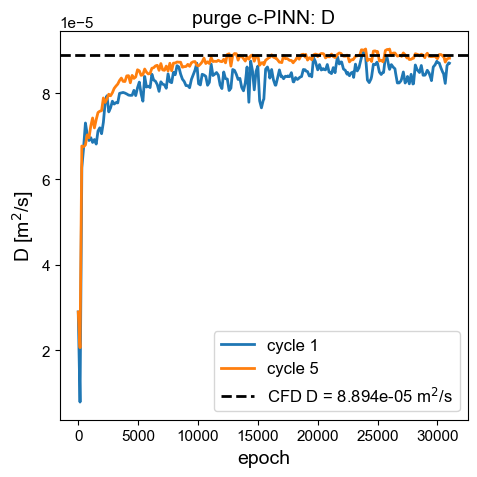

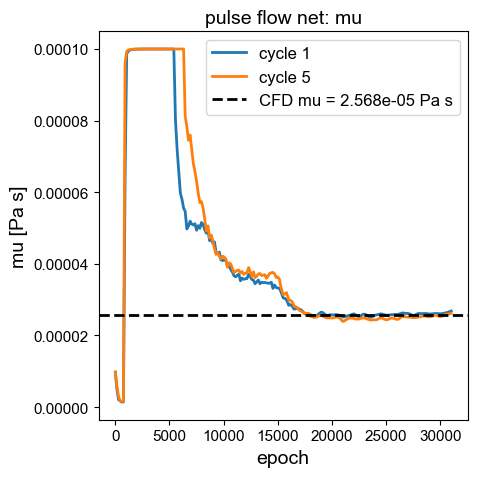

In [8]:
detail = json_util.load_json(RESULT / "slide_case_detail.json")
NET_LABEL = {"purge": "purge c-PINN", "flow": "pulse flow net"}
for key, unit, loc in (("D", "m$^2$/s", "lower right"), ("mu", "Pa s", "upper right")):
    subs = sorted((h for h in detail["history"].values() if h["param"] == key), key=lambda h: h["cycle"])
    if not subs:
        print(f"slide_case_detail.json has no {key} history yet: run the cell above first")
        continue
    fig, ax = plt.subplots(figsize=(5, 5))
    for h in subs:
        pinn_training.PINNTraining.plot_params(h, params=[key], axes=[ax], label=f"cycle {h['cycle']}")
    ax.axhline(subs[0]["true"], color="k", ls="--", label=f"CFD {key} = {subs[0]['true']:.4g} {unit}")
    ax.set_ylabel(f"{key} [{unit}]")
    ax.set_title(f"{NET_LABEL[subs[0]['net']]}: {key}")
    ax.legend(loc=loc)
    fig.tight_layout()
    fig.savefig(FIGURE / f"slide_{key}_history.png")
    plt.show()

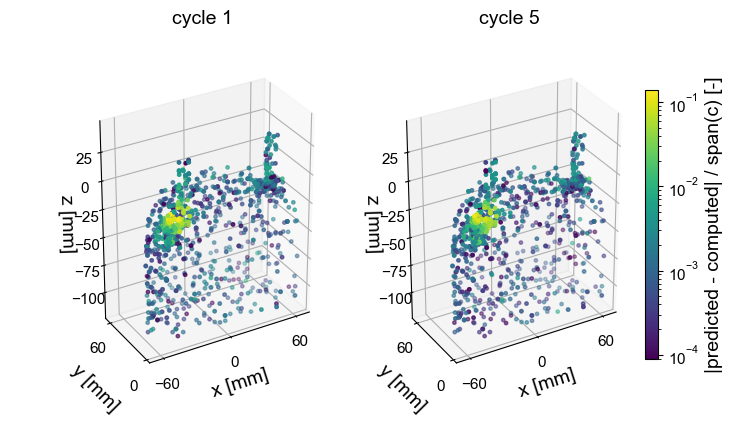

In [9]:
detail = json_util.load_json(RESULT / "slide_case_detail.json")
subs = sorted(detail["scatter"].values(), key=lambda s: s["cycle"])
err_all = np.concatenate([np.asarray(s["rel_err"]) for s in subs])
norm = matplotlib.colors.LogNorm(vmin=np.percentile(err_all, 5), vmax=err_all.max())
fig, axes = plt.subplots(1, len(subs), figsize=(5 * len(subs), 5), subplot_kw={"projection": "3d"})
axes = np.ravel(axes)
fig.subplots_adjust(left=0.0, right=0.95, wspace=-0.45)
for ax, s in zip(axes, subs):
    xyz, err = np.asarray(s["xyz_mm"]), np.asarray(s["rel_err"])
    order = np.argsort(err)
    sc = ax.scatter(*xyz[order].T, c=err[order], s=6, cmap="viridis", norm=norm)
    ax.view_init(elev=30, azim=-120)
    ax.set_box_aspect(np.ptp(xyz, axis=0), zoom=0.78)
    ax.set_xticks([-60, 0, 60])
    ax.set_yticks([0, 60])
    ax.set_xlabel("x [mm]", labelpad=8)
    ax.set_ylabel("y [mm]", labelpad=8)
    ax.set_zlabel("z [mm]")
    ax.set_title(f"cycle {s['cycle']}")
fig.colorbar(sc, ax=list(axes), shrink=0.7, pad=-0.06, label="|predicted - computed| / span(c) [-]")
fig.savefig(FIGURE / "slide_purge_error_scatter.png")
plt.show()

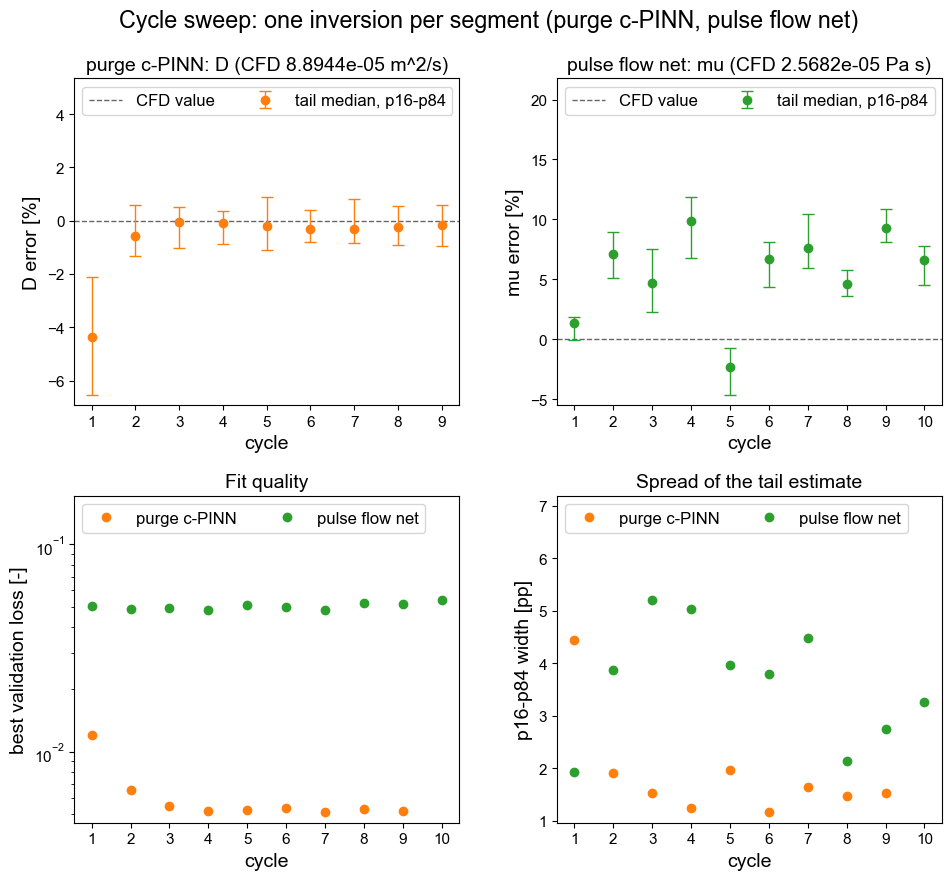

In [10]:
summary = json_util.load_json(RESULT / "sweep_summary.json")
rows = [r for r in summary["rows"] if "param" in r]
if not rows:
    print("sweep_summary.json has no inversion case yet: run the sweep first")
else:
    style = lambda r: dict(marker="o", ls="none", mfc="none" if r["at_bound"] else None)
    by_net = lambda net: sorted((r for r in rows if r["net"] == net), key=lambda r: r["index"])
    COLOR = {"purge": const.SPLIT_COLORS["valid"], "flow": const.SPLIT_COLORS["test"]}
    LABEL = {"purge": "purge c-PINN", "flow": "pulse flow net"}

    def headroom(ax, frac=0.4):
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi * (hi / lo) ** frac if ax.get_yscale() == "log" else hi + frac * (hi - lo))

    n_cycle = max(r["index"] for r in rows)
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))
    fig.suptitle("Cycle sweep: one inversion per segment (purge c-PINN, pulse flow net)")
    for col, (net, key, unit) in enumerate((("purge", "D", "m^2/s"), ("flow", "mu", "Pa s"))):
        sub, ax = by_net(net), axes[0, col]
        ax.axhline(0.0, color="0.4", ls="--", lw=1, label="CFD value")
        ax.set_xlabel("cycle")
        ax.set_ylabel(f"{key} error [%]")
        if not sub:
            continue
        good = [r for r in sub if not r["at_bound"]]
        ax.errorbar([r["index"] for r in good], [100.0 * r["rel_error"] for r in good],
                    yerr=[[r["lo_pp"] for r in good], [r["hi_pp"] for r in good]],
                    color=COLOR[net], marker="o", ls="none", capsize=4, elinewidth=1,
                    label="tail median, p16-p84")
        ax.set_xticks([r["index"] for r in sub])
        ax.set_title(f"{LABEL[net]}: {key} (CFD {sub[0]['true']:.4e} {unit})")
        headroom(ax, 0.5)
        ax.legend(ncol=2, loc="upper left")
        lo, hi = ax.get_ylim()
        blown = [r for r in sub if r["at_bound"]]
        for r in blown:
            ax.plot(r["index"], hi, color=COLOR[net], marker="^", ls="none", clip_on=False)
        if blown:
            ax.text(0.97, 0.04, "off scale: " + ", ".join(f"cycle {r['index']} {100.0 * r['rel_error']:+.0f}%"
                                                          for r in blown)
                    + f"\n{key} ran to the search bound {blown[0]['bounds'][1]:.0e}",
                    transform=ax.transAxes, ha="right", va="bottom", fontsize=10, color=COLOR[net])
        ax.set_ylim(lo, hi)
    for col, (field, label, title, logy) in enumerate(
            (("best_val", "best validation loss [-]", "Fit quality", True),
             ("spread_pp", "p16-p84 width [pp]", "Spread of the tail estimate", False))):
        ax = axes[1, col]
        for net in ("purge", "flow"):
            sub = by_net(net)
            for r in sub:
                ax.plot(r["index"], r[field], color=COLOR[net], **style(r))
            if sub:
                ax.plot([], [], color=COLOR[net], marker="o", ls="none", label=LABEL[net])
        if any(r["at_bound"] for r in rows):
            ax.plot([], [], color="0.4", marker="o", mfc="none", ls="none", label="on search bound")
        if logy:
            ax.set_yscale("log")
        ax.set_xticks(range(1, n_cycle + 1))
        ax.set_xlabel("cycle")
        ax.set_ylabel(label)
        ax.set_title(title)
        headroom(ax)
        ax.legend(ncol=3, loc="upper left")
    fig.tight_layout()
    fig.savefig(FIGURE / "sweep_params.png")
    plt.show()

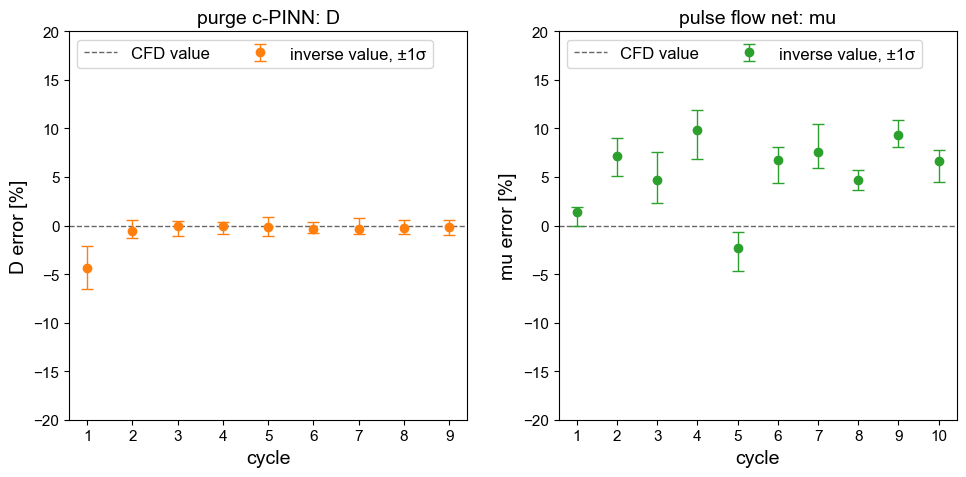

In [11]:
summary = json_util.load_json(RESULT / "sweep_summary.json")
rows = [r for r in summary["rows"] if "param" in r]
if not rows:
    print("sweep_summary.json has no inversion case yet: run the sweep first")
else:
    by_net = lambda net: sorted((r for r in rows if r["net"] == net), key=lambda r: r["index"])
    COLOR = {"purge": const.SPLIT_COLORS["valid"], "flow": const.SPLIT_COLORS["test"]}
    LABEL = {"purge": "purge c-PINN", "flow": "pulse flow net"}

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for col, (net, key) in enumerate((("purge", "D"), ("flow", "mu"))):
        sub, ax = by_net(net), axes[col]
        ax.axhline(0.0, color="0.4", ls="--", lw=1, label="CFD value")
        ax.set_xlabel("cycle")
        ax.set_ylabel(f"{key} error [%]")
        ax.set_title(f"{LABEL[net]}: {key}")
        if not sub:
            continue
        good = [r for r in sub if not r["at_bound"]]
        ax.errorbar(
            [r["index"] for r in good],
            [100.0 * r["rel_error"] for r in good],
            yerr=[[r["lo_pp"] for r in good], [r["hi_pp"] for r in good]],
            color=COLOR[net],
            marker="o",
            ls="none",
            capsize=4,
            elinewidth=1,
            label="inverse value, ±1σ",
        )
        ax.set_xticks([r["index"] for r in sub])
        lo, hi = ax.get_ylim()
        ax.set_ylim(-20, 20)
        ax.legend(ncol=2, loc="upper left")
        lo, hi = ax.get_ylim()
        blown = [r for r in sub if r["at_bound"]]
        for r in blown:
            ax.plot(r["index"], hi, color=COLOR[net], marker="^", ls="none", clip_on=False)
        if blown:
            ax.text(
                0.97,
                0.04,
                "off scale: " + ", ".join(f"cycle {r['index']} {100.0 * r['rel_error']:+.0f}%" for r in blown) + f"\n{key} ran to the search bound {blown[0]['bounds'][1]:.0e}",
                transform=ax.transAxes,
                ha="right",
                va="bottom",
                fontsize=10,
                color=COLOR[net],
            )
        ax.set_ylim(lo, hi)
    fig.tight_layout()
    fig.savefig(FIGURE / "sweep_params_top.png")
    plt.show()

In [12]:
if RERUN_SWEEP:
    FIELD_ERROR_WHIS = (5, 95)
    rows = []
    for name in ORDER:
        path = RESULT / f"{name}.json"
        if not path.exists():
            continue
        rec = json_util.load_json(path)
        test, net = rec["test"], rec["net"]
        err = {}
        if net == "flow":
            comp = np.column_stack([test[f]["computed"] for f in ("u", "v", "w")])
            pred = np.column_stack([test[f]["predicted"] for f in ("u", "v", "w")])
            err["u"] = np.linalg.norm(pred - comp, axis=1) / np.ptp(np.linalg.norm(comp, axis=1))
            err["p"] = np.abs(np.asarray(test["p"]["predicted"]) - np.asarray(test["p"]["computed"])) / np.ptp(test["p"]["computed"])
        else:
            err["c"] = np.abs(np.asarray(test["c"]["predicted"]) - np.asarray(test["c"]["computed"])) / np.ptp(test["c"]["computed"])
        index = int(re.fullmatch(r"(?:pulse|purge)(\d*)_.*", name)[1] or 1)
        for field, e in err.items():
            q = np.percentile(100.0 * e, [FIELD_ERROR_WHIS[0], 25, 50, 75, FIELD_ERROR_WHIS[1]])
            rows.append({"case": name, "net": net, "index": index, "field": field, "n": int(e.size),
                         "box": {"whislo": float(q[0]), "q1": float(q[1]), "med": float(q[2]),
                                 "q3": float(q[3]), "whishi": float(q[4])}})
    json_util.save_json(RESULT / "sweep_field_error.json", {"rows": rows, "whiskers": list(FIELD_ERROR_WHIS)})

    print(f"{len(rows)} case-field pairs from {len({r['case'] for r in rows})} cases (test split, error / span in %)")
    print(f"\n{'case':<16}{'field':<7}{'n':>7}{'p5':>9}{'q1':>9}{'median':>9}{'q3':>9}{'p95':>9}")
    for r in rows:
        b = r["box"]
        print(f"{r['case']:<16}{r['field']:<7}{r['n']:>7}" + "".join(f"{b[k]:>9.3f}"
              for k in ("whislo", "q1", "med", "q3", "whishi")))

39 case-field pairs from 29 cases (test split, error / span in %)

case            field        n       p5       q1   median       q3      p95
purge_D         c         1189    0.010    0.057    0.121    0.311    4.662
purge2_D        c         1189    0.007    0.036    0.095    0.295    4.534
purge3_D        c         1189    0.008    0.045    0.123    0.317    4.293
purge4_D        c         1189    0.008    0.039    0.107    0.294    4.071
purge5_D        c         1189    0.008    0.044    0.105    0.304    4.105
purge6_D        c         1189    0.007    0.043    0.103    0.300    4.145
purge7_D        c         1189    0.008    0.040    0.097    0.239    3.802
purge8_D        c         1189    0.009    0.039    0.105    0.299    4.154
purge9_D        c         1189    0.009    0.046    0.121    0.323    4.108
pulse_flow_mu   u         1189    0.146    0.365    0.687    2.073    9.199
pulse_flow_mu   p         1189    0.006    0.041    0.112    0.786    2.278
pulse2_flow_mu  u    

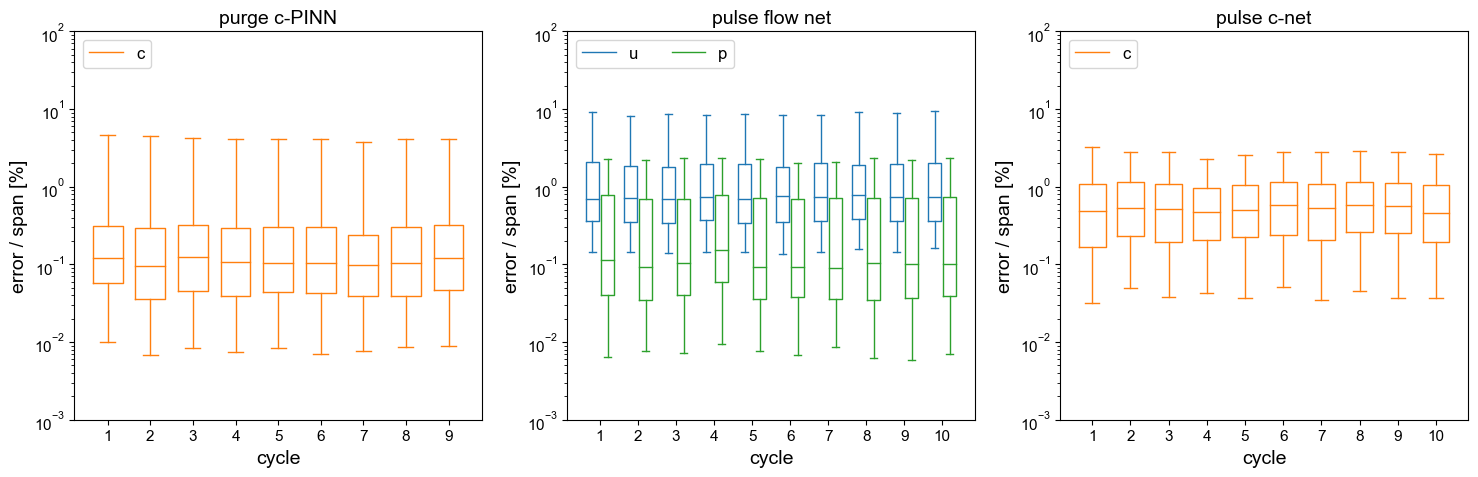

In [13]:
FE = json_util.load_json(RESULT / "sweep_field_error.json")
rows = FE["rows"]
if not rows:
    print("sweep_field_error.json has no case yet: run the cell above first")
else:
    FIELD_COLOR = {"c": "tab:orange", "u": "tab:blue", "p": "tab:green"}
    BOX = {(r["net"], r["index"], r["field"]): r["box"] for r in rows}
    PANELS = (("purge", ("c",), "purge c-PINN"), ("flow", ("u", "p"), "pulse flow net"), ("cnet", ("c",), "pulse c-net"))

    fig, axes = plt.subplots(1, 3, figsize=(5 * 3, 5))
    for ax, (net, fields, title) in zip(axes, PANELS):
        idx = sorted({r["index"] for r in rows if r["net"] == net})
        for j, field in enumerate(fields):
            boxes = [BOX[(net, i, field)] for i in idx if (net, i, field) in BOX]
            pos = [i + (j - (len(fields) - 1) / 2) * 0.8 / len(fields) for i in idx if (net, i, field) in BOX]
            if not boxes:
                continue
            props = {"color": FIELD_COLOR[field]}
            art = ax.bxp(
                boxes, positions=pos, widths=0.7 / len(fields), showfliers=False, manage_ticks=False, boxprops=props, whiskerprops=props, capprops=props, medianprops=props
            )
            art["boxes"][0].set_label(field)
        ax.set_yscale("log")
        ax.set_xticks(idx)
        ax.set_xlabel("cycle")
        ax.set_ylabel("error / span [%]")
        ax.set_title(title)
        lo, hi = ax.get_ylim()
        ax.set_ylim(1e-3, 1e2)
        ax.legend(ncol=len(fields), loc="upper left")
    fig.tight_layout()
    fig.savefig(FIGURE / "sweep_field_error.png")
    plt.show()

## Sweep Results

## Dose: Outlet Flux

In [14]:
RUN_DOSE_CFD = False
DOSE_CFD_JSON = RESULT / "dose_cfd.json"
OUTLET_NODES, OUTLET_W = dose.outlet_quadrature(mesh, meta)
INLET_NODES, INLET_W = comsol_case.face_quadrature(mesh, comsol_case.faces_of(meta, "spf", "inlet"))
Q_KNOWN = dose.known_flow_rate(meta)
_stale = DOSE_CFD_JSON.exists() and "check" not in json_util.load_json(DOSE_CFD_JSON)
if RUN_DOSE_CFD or not DOSE_CFD_JSON.exists() or _stale:
    ref = {"cycle": [], "s": [], "t": [], "q": [], "dose_window": [], "dose_segment": [], "check": [],
           "window": list(const.CFD_T_WINDOW), "n_outlet_nodes": int(OUTLET_NODES.size),
           "outlet_area": float(np.abs(OUTLET_W.sum(axis=0)).max()), "q_known": Q_KNOWN}
    for index in range(1, len(const.CFD_PULSE_FLOW_CASES) + 1):
        field = np.load(field_paths[SEG_LABEL[("pulse", index)]])
        rel = field["times"] - field["times"][0]
        q = dose.mass_rate(dose.cfd_flux(field, PERM, OUTLET_NODES, OUTLET_W))
        ref["cycle"].append(index)
        ref["s"].append(float(SEGMENT[f"pulse{cycle_tag(index)}_flow"]["snapshot"][:, -1].mean()))
        ref["t"].append(rel)
        ref["q"].append(q)
        ref["dose_window"].append(dose.window_dose(rel, q, *const.CFD_T_WINDOW))
        ref["dose_segment"].append(dose.window_dose(rel, q, rel[0], rel[-1]))
        rows = lambda ids: np.asarray(PERM)[np.asarray(ids)]
        q_out = np.einsum("itk,ik->t", field["vel_data"][rows(OUTLET_NODES)][:, :, 1:4], OUTLET_W)
        q_in = np.einsum("itk,ik->t", field["vel_data"][rows(INLET_NODES)][:, :, 1:4], INLET_W)
        duty = comsol_case.pulse_waveform(field["times"], meta["pulse_schedule"])
        win = (rel >= const.CFD_T_WINDOW[0] - 1e-9) & (rel <= const.CFD_T_WINDOW[1] + 1e-9)
        mid = int(np.argmin(np.abs(duty - 0.5)))
        ref["check"].append({"out_rel": float(q_out[win].mean() / Q_KNOWN - 1),
                             "in_rel": float(-q_in[win].mean() / Q_KNOWN - 1),
                             "balance": float(np.abs(q_out + q_in).max() / Q_KNOWN),
                             "mid_ramp": float(q_out[mid] / Q_KNOWN), "mid_ramp_rect": float(duty[mid])})
    json_util.save_json(DOSE_CFD_JSON, ref)
DOSE_CFD = json_util.load_json(DOSE_CFD_JSON)
DOSE_BY = dict(zip(DOSE_CFD["cycle"], DOSE_CFD["dose_window"]))
S_BY = dict(zip(DOSE_CFD["cycle"], DOSE_CFD["s"]))
T_REL = np.asarray(DOSE_CFD["t"][0])
for t in DOSE_CFD["t"][1:]:
    np.testing.assert_allclose(t, T_REL, atol=1e-9)
IN_WINDOW = (T_REL >= const.CFD_T_WINDOW[0] - 1e-9) & (T_REL <= const.CFD_T_WINDOW[1] + 1e-9)
DUTY = comsol_case.pulse_waveform(T_REL, meta["pulse_schedule"])
assert np.allclose(DUTY[IN_WINDOW], 1.0), "the dose window must sit inside the injection plateau"

print(f"outlet face: {DOSE_CFD['n_outlet_nodes']} mesh nodes, area {DOSE_CFD['outlet_area'] * 1e6:.1f} mm^2 "
      f"(half of pi r^2 = {0.5 * np.pi * const.CFD_TUBE_R_IN ** 2 * 1e6:.1f} mm^2); "
      f"{int(IN_WINDOW.sum())} of {T_REL.size} stored instants fall inside the window {list(const.CFD_T_WINDOW)} s")
print(f"{'cycle':>5}{'s':>8}{'peak q [mg/s]':>15}{'dose window [mg]':>18}{'dose segment [mg]':>19}{'window/segment':>16}")
for k, s, q, dw, dsg in zip(DOSE_CFD["cycle"], DOSE_CFD["s"], DOSE_CFD["q"], DOSE_CFD["dose_window"], DOSE_CFD["dose_segment"]):
    print(f"{k:>5}{s:>8.4f}{np.max(q):>15.4f}{dw:>18.4f}{dsg:>19.4f}{dw / dsg:>16.3f}")

print(f"\nknown outlet volumetric flow Q_known = {DOSE_CFD['q_known'] * 1e3:.5f} L/s (half model, plateau), "
      f"from the inlet BC: Fin/{const.CFD_HALF_MODEL_FACTOR:.0f} sccm at standard state")
print(f"{'cycle':>6}{'Qout/Qk-1':>12}{'|Qin|/Qk-1':>12}{'max|Qout+Qin|/Qk':>18}{'rect':>7}{'Qout/Qk there':>15}")
for k, ck in zip(DOSE_CFD["cycle"], DOSE_CFD["check"]):
    print(f"{k:>6}{ck['out_rel']:>+12.4%}{ck['in_rel']:>+12.4%}{ck['balance']:>18.2e}"
          f"{ck['mid_ramp_rect']:>7.3f}{ck['mid_ramp']:>15.6f}")
_worst = max(DOSE_CFD["check"], key=lambda c: abs(c["out_rel"]))
assert abs(_worst["out_rel"]) <= const.CFD_QVOL_CHECK_TOL, (
    f"CFD outlet volumetric flow is {_worst['out_rel']:+.3%} off the known inlet flow rate: constant density no longer "
    f"holds, so dose must not use Q_known (see notebook section 2.2)")
_bal = max(c["balance"] for c in DOSE_CFD["check"])
assert _bal <= const.CFD_MASS_BALANCE_TOL, f"inlet and outlet volumetric flows do not balance: {_bal:.2e} of Q_known"
print(f"premise holds: worst window-mean deviation {_worst['out_rel']:+.3%} (tolerance {const.CFD_QVOL_CHECK_TOL:.1%}), "
      f"worst two-port imbalance {_bal:.1e} of Q_known (tolerance {const.CFD_MASS_BALANCE_TOL:.0e}); "
      f"the last two columns show the outlet tracks the analytic rect with no lag")

outlet face: 30 mesh nodes, area 35.3 mm^2 (half of pi r^2 = 36.9 mm^2); 181 of 301 stored instants fall inside the window [0.6, 2.4] s
cycle       s  peak q [mg/s]  dose window [mg]  dose segment [mg]  window/segment
    1  0.8149         1.5619            2.2282             2.4756           0.900
    2  0.5485         1.1196            1.5992             1.7592           0.909
    3  0.4883         1.0288            1.4586             1.5991           0.912
    4  0.4747         1.0068            1.4261             1.5607           0.914
    5  0.4720         1.0028            1.4204             1.5555           0.913
    6  0.4710         1.0013            1.4182             1.5529           0.913
    7  0.4708         1.0010            1.4177             1.5524           0.913
    8  0.4708         1.0009            1.4176             1.5522           0.913
    9  0.4707         1.0009            1.4175             1.5522           0.913
   10  0.4707         1.0009            1.41

In [15]:
RERUN_DOSE = False
if RERUN_DOSE:
    PROFILE_T = 1.5
    PROFILE_N = 200


    def pinn_window_dose(c_model, v_model, scales, s=None):
        t_star = T_REL[IN_WINDOW] / scales["tau"]
        q = dose.mass_rate(dose.pinn_flux(c_model, v_model, mesh["vertices"][OUTLET_NODES], OUTLET_W, t_star, scales,
                                          CNET_FIELDS, FLOW_FIELDS, Q_KNOWN * DUTY[IN_WINDOW], s=s))
        return dose.window_dose(T_REL[IN_WINDOW], q, *const.CFD_T_WINDOW), q


    def pinn_qvol_error(v_model, scales, s=None):
        qv = dose.pinn_qvol(v_model, mesh["vertices"][OUTLET_NODES], OUTLET_W, T_REL[IN_WINDOW] / scales["tau"],
                            scales, FLOW_FIELDS, s=s)
        return float(np.mean(qv / (Q_KNOWN * DUTY[IN_WINDOW]) - 1))


    OUTLET_XYZ = mesh["vertices"][OUTLET_NODES]
    OUTLET_Z = float(np.unique(np.round(OUTLET_XYZ[:, 2], 9)).item())
    OUTLET_AXIS = np.array([float(np.round((OUTLET_XYZ[:, 0].min() + OUTLET_XYZ[:, 0].max()) / 2, 9)), 0.0])


    def outlet_w_profile(v_model, scales, s=None):
        r = np.linspace(0.0, const.CFD_TUBE_R_IN, PROFILE_N)
        xyz = np.column_stack([np.full_like(r, OUTLET_AXIS[0]), r, np.full_like(r, OUTLET_Z)]) / scales["L"]
        cols = [xyz, np.full((r.size, 1), PROFILE_T / scales["tau"])]
        if s is not None:
            cols.append(np.full((r.size, 1), float(s)))
        X = torch.as_tensor(np.column_stack(cols), dtype=next(v_model.parameters()).dtype,
                            device=next(v_model.parameters()).device)
        with torch.no_grad():
            w = v_model(X)[:, FLOW_FIELDS.index("w")].cpu().numpy()
        return r, w * scales["U"]


    rows = []
    profiles = {}
    for index in range(1, len(const.CFD_PULSE_FLOW_CASES) + 1):
        tag = cycle_tag(index)
        if not ((RESULT / f"pulse{tag}_c.pt").exists() and (RESULT / f"pulse{tag}_flow_mu.pt").exists()):
            continue
        c_model, _ = pinn_training.PINNTraining.load_checkpoint(RESULT / f"pulse{tag}_c.pt", feature=FEATURE)
        v_model, _ = pinn_training.PINNTraining.load_checkpoint(RESULT / f"pulse{tag}_flow_mu.pt", feature=FEATURE)
        scales = SEGMENT[f"pulse{tag}_flow"]["scales"]
        dose_window, q = pinn_window_dose(c_model, v_model, scales)
        rows.append({"case": f"pulse{tag}_c", "cycle": index, "dose": dose_window, "cfd": DOSE_BY[index],
                     "rel_error": dose_window / DOSE_BY[index] - 1, "qvol_err": pinn_qvol_error(v_model, scales), "q": q,
                     "q_cfd": np.asarray(DOSE_CFD["q"][list(DOSE_CFD["cycle"]).index(index)])[IN_WINDOW]})
        r_dense, w_dense = outlet_w_profile(v_model, scales)
        profiles[str(index)] = w_dense
    json_util.save_json(RESULT / "sweep_dose.json",
                        {"rows": rows, "t": T_REL[IN_WINDOW], "window": list(const.CFD_T_WINDOW)})

    if rows:
        _field = np.load(field_paths[SEG_LABEL[("pulse", rows[0]["cycle"])]])
        _k = int(np.argmin(np.abs(_field["times"] - _field["times"][0] - PROFILE_T)))
        _xy = OUTLET_XYZ[:, :2] - OUTLET_AXIS[None, :]
        json_util.save_json(RESULT / "outlet_profile.json",
                            {"t_rel": PROFILE_T, "r_wall": const.CFD_TUBE_R_IN, "r_dense": r_dense,
                             "w_pinn": profiles, "r_cfd": np.linalg.norm(_xy, axis=1),
                             "w_cfd": _field["vel_data"][np.asarray(PERM)[OUTLET_NODES], _k, 3]})

    print(f"{len(rows)} of {len(const.CFD_PULSE_CNET_CASES)} cycles have both nets\n")
    print(f"{'cycle':>6}{'PINN [mg]':>12}{'CFD [mg]':>12}{'rel error':>12}{'Qvol err':>12}")
    for r in rows:
        print(f"{r['cycle']:>6}{r['dose']:>12.4f}{r['cfd']:>12.4f}{r['rel_error']:>+12.2%}{r['qvol_err']:>+12.2%}")
    if rows:
        e = [r["rel_error"] for r in rows]
        qv = [r["qvol_err"] for r in rows]
        print(f"\nwindow dose vs CFD over {len(e)} cycles: median {np.median(e):+.2%}, "
              f"min {min(e):+.2%}, max {max(e):+.2%}")
        print(f"diagnostic only, not used by dose: the flow nets' own outlet volumetric flow is "
              f"{min(qv):+.2%} .. {max(qv):+.2%} off Q_known -- the near-wall ring of the outlet face is under-resolved")

10 of 10 cycles have both nets

 cycle   PINN [mg]    CFD [mg]   rel error    Qvol err
     1      2.2399      2.2282      +0.53%      -2.90%
     2      1.6119      1.5992      +0.80%      -3.56%
     3      1.4677      1.4586      +0.63%      -4.05%
     4      1.4344      1.4261      +0.58%      -4.26%
     5      1.4271      1.4204      +0.47%      -2.68%
     6      1.4249      1.4182      +0.48%      -3.23%
     7      1.4239      1.4177      +0.44%      -3.68%
     8      1.4292      1.4176      +0.82%      -3.67%
     9      1.4227      1.4175      +0.36%      -4.49%
    10      1.4179      1.4175      +0.02%      -4.88%

window dose vs CFD over 10 cycles: median +0.50%, min +0.02%, max +0.82%
diagnostic only, not used by dose: the flow nets' own outlet volumetric flow is -4.88% .. -2.68% off Q_known -- the near-wall ring of the outlet face is under-resolved


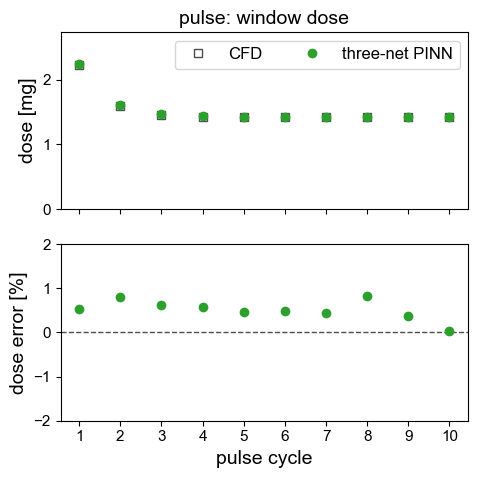

In [16]:
SD = json_util.load_json(RESULT / "sweep_dose.json")
rows = SD["rows"]
if not rows:
    print("sweep_dose.json has no cycle yet: run the cell above first")
else:
    cycle = [r["cycle"] for r in rows]
    fig, axes = plt.subplots(2, 1, figsize=(5, 5), sharex=True)
    ax = axes[0]
    ax.plot(cycle, [r["cfd"] for r in rows], color="0.3", marker="s", mfc="none", ls="none", label="CFD")
    ax.plot(cycle, [r["dose"] for r in rows], color=const.SPLIT_COLORS["test"], marker="o", ls="none",
            label="three-net PINN")
    ax.set_ylabel("dose [mg]")
    ax.set_title("pulse: window dose")
    lo, hi = ax.get_ylim()
    ax.set_ylim(0, hi + 0.5 * (hi - lo))
    ax.legend(ncol=2, loc="upper right")
    ax = axes[1]
    ax.axhline(0.0, color="0.3", ls="--", lw=1)
    ax.plot(cycle, [100.0 * r["rel_error"] for r in rows], color=const.SPLIT_COLORS["test"], marker="o", ls="none")
    ax.set_xticks(cycle)
    ax.set_xlabel("pulse cycle")
    ax.set_ylabel("dose error [%]")
    ax.set_ylim(-2, 2)
    fig.tight_layout()
    fig.savefig(FIGURE / "sweep_dose.png")
    plt.show()

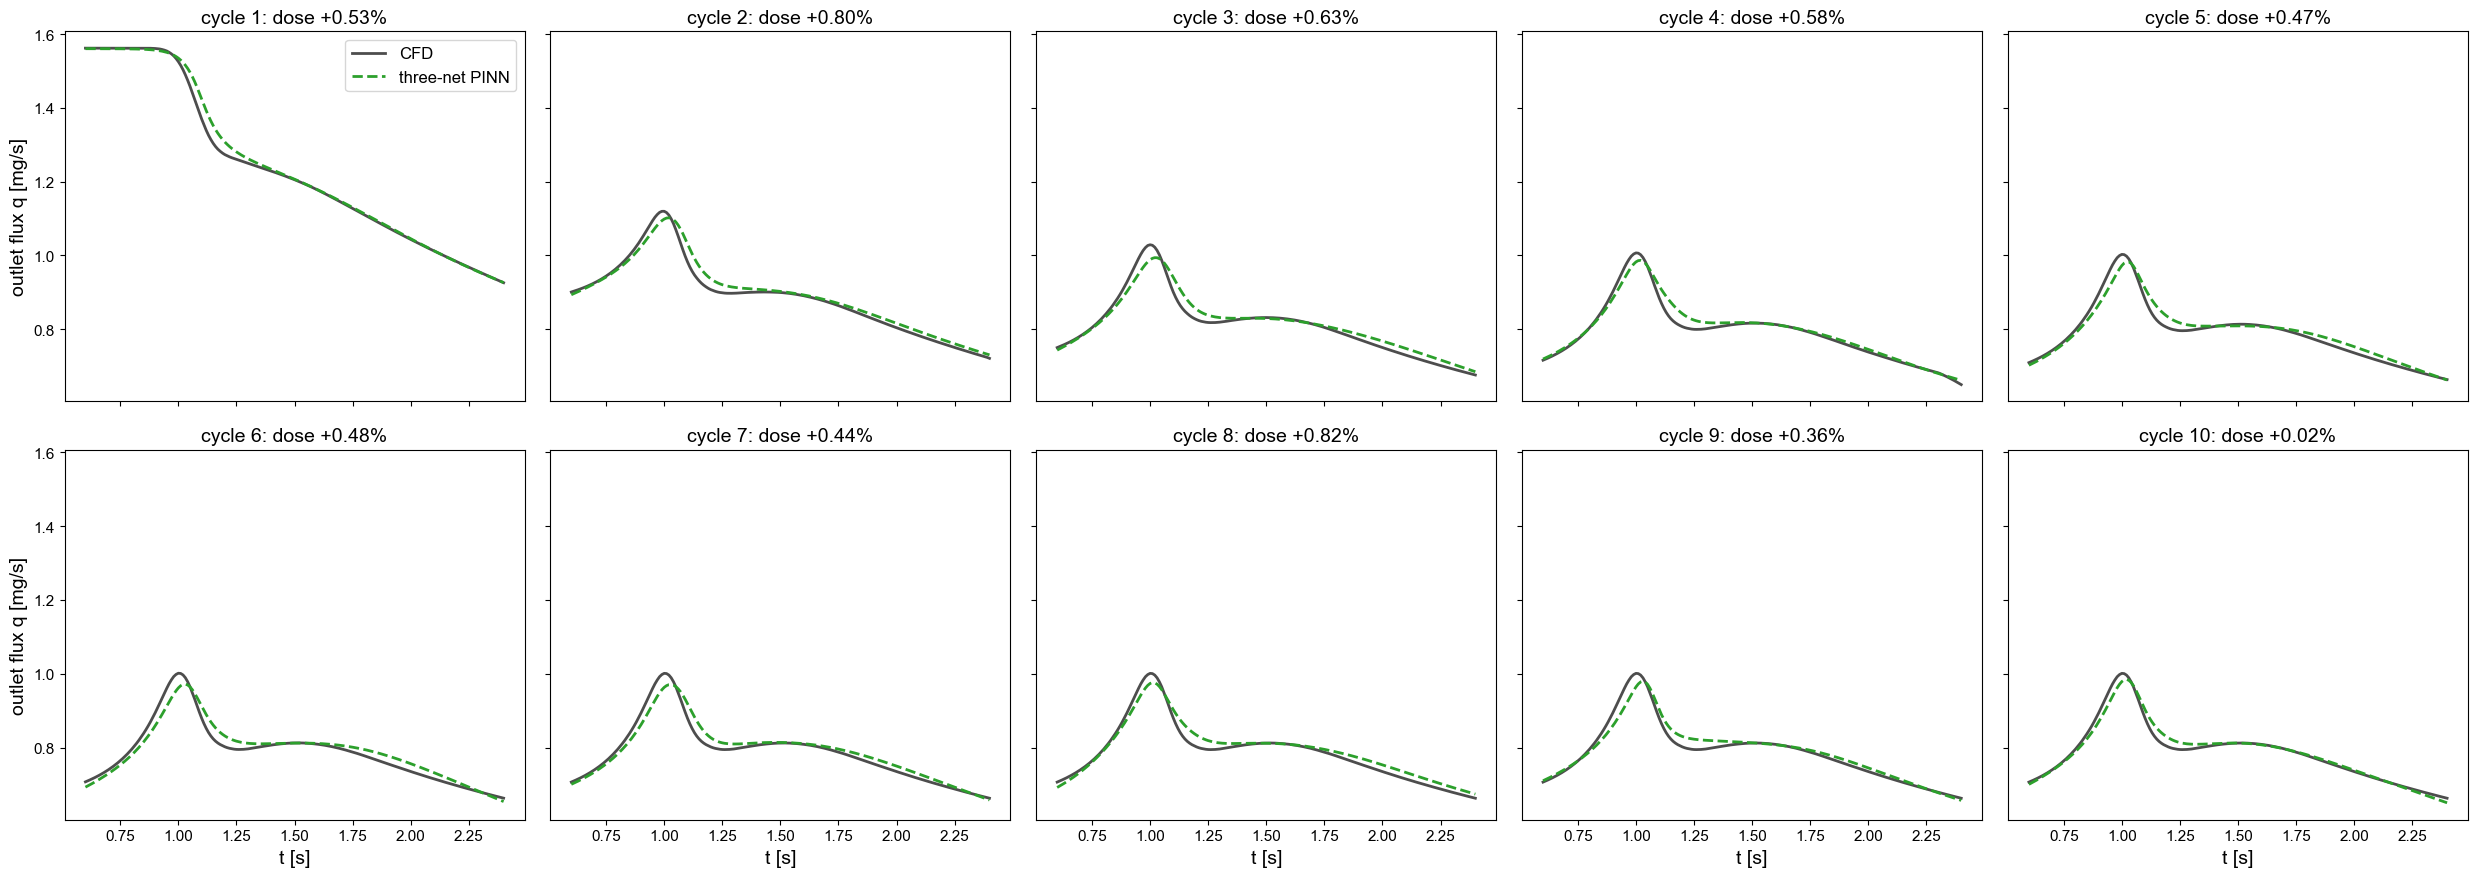

In [17]:
SD = json_util.load_json(RESULT / "sweep_dose.json")
rows = SD["rows"]
if not rows:
    print("sweep_dose.json has no cycle yet: run the cell above first")
else:
    t = np.asarray(SD["t"])
    ncols = 5
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows + 1), sharex=True, sharey=True, squeeze=False)
    for ax, r in zip(axes.ravel(), rows):
        ax.plot(t, np.asarray(r["q_cfd"]), color="0.3", label="CFD")
        ax.plot(t, np.asarray(r["q"]), color=const.SPLIT_COLORS["test"], ls="--", label="three-net PINN")
        ax.set_title(f"cycle {r['cycle']}: dose {r['rel_error']:+.2%}")
    for ax in axes[:, 0]:
        ax.set_ylabel("outlet flux q [mg/s]")
    for ax in axes[-1, :]:
        ax.set_xlabel("t [s]")
    for ax in axes.ravel()[len(rows):]:
        ax.axis("off")
    axes[0, 0].legend()
    fig.tight_layout()
    fig.savefig(FIGURE / "sweep_dose_q.png")
    plt.show()

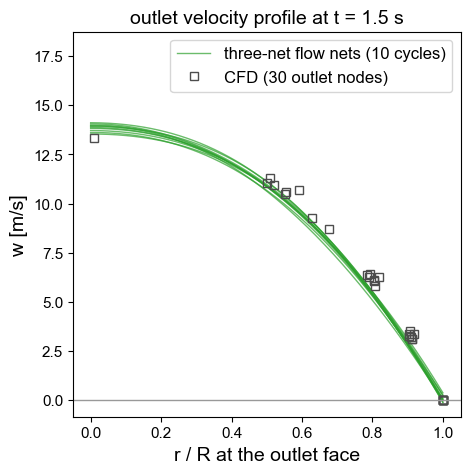

In [18]:
PF = json_util.load_json(RESULT / "outlet_profile.json")
r_wall = PF["r_wall"]
fig, ax = plt.subplots(figsize=(5, 5))
r_dense = np.asarray(PF["r_dense"]) / r_wall
for k, (cycle, w) in enumerate(sorted(PF["w_pinn"].items(), key=lambda kv: int(kv[0]))):
    ax.plot(r_dense, np.asarray(w), color=const.SPLIT_COLORS["test"], lw=1, alpha=0.7,
            label="three-net flow nets (10 cycles)" if k == 0 else None)
ax.plot(np.asarray(PF["r_cfd"]) / r_wall, np.asarray(PF["w_cfd"]), color="0.3", marker="s", mfc="none", ls="none",
        label="CFD (30 outlet nodes)")
ax.axhline(0.0, color="0.6", lw=1)
ax.set_xlabel("r / R at the outlet face")
ax.set_ylabel("w [m/s]")
ax.set_title(f"outlet velocity profile at t = {PF['t_rel']} s")
lo, hi = ax.get_ylim()
ax.set_ylim(lo, hi + 0.25 * (hi - lo))
ax.legend()
fig.savefig(FIGURE / "outlet_w_profile.png")
plt.show()

# Merged PINN

In [19]:
if FIELD_DATA:
    MERGED_CYCLES = {kind: [i for i in range(1, n + 1) if i != const.CFD_MERGED_HOLDOUT]
                     for kind, n in (("pulse", len(const.CFD_PULSE_FLOW_CASES)),
                                     ("purge", len(const.CFD_PURGE_SWEEP_CASES)))}
    SHARED_SCALES = {kind: {k: v for k, v in SEGMENT[f"{kind}{'' if kind == 'purge' else '_flow'}"]["scales"].items()
                            if k != "t0"} for kind in ("pulse", "purge")}


    def build_merged(kind, cycles):
        segs = [build_segment(kind, i, scales=SHARED_SCALES[kind], n_data=const.CFD_MERGED_N_DATA) for i in cycles]
        for seg in segs[1:]:
            assert seg["param_scale"] == segs[0]["param_scale"] and seg["window"]["n_times"] == segs[0]["window"]["n_times"]
            np.testing.assert_allclose(seg["t_range"], segs[0]["t_range"], rtol=1e-9)
            for key in seg["true_dim"]:
                np.testing.assert_allclose(seg["true_dim"][key], segs[0]["true_dim"][key], rtol=1e-9)
        s_values = np.array([float(seg["snapshot"][:, -1].mean()) for seg in segs])
        assert np.unique(s_values).size == len(cycles), f"{kind}: two cycles share the same s: {s_values}"
        n = [seg["dataset"]["X"].shape[0] for seg in segs]
        dataset = {"X": np.vstack([np.column_stack([seg["dataset"]["X"], np.full(m, s)])
                                   for seg, m, s in zip(segs, n, s_values)]),
                   "node": np.concatenate([seg["dataset"]["node"] for seg in segs]),
                   "time_index": np.concatenate([seg["dataset"]["time_index"] for seg in segs]),
                   "segment": np.repeat(np.arange(len(cycles)), n), "cycle": np.repeat(np.asarray(cycles), n)}
        for f in ("c", *FLOW_FIELDS) if kind == "pulse" else ("c",):
            dataset[f] = np.concatenate([seg["dataset"][f] for seg in segs])
        return {**segs[0], "cycles": list(cycles), "s_values": s_values, "dataset": dataset,
                "snapshot": np.stack([seg["snapshot"] for seg in segs]), "window": [seg["window"] for seg in segs],
                "scales": SHARED_SCALES[kind], "hidden": const.CFD_MERGED_HIDDEN, "num_node": const.CFD_MERGED_NUM_NODE}


    def merged_views(merged):
        n_seg = merged["snapshot"].shape[0]
        if merged["kind"] == "purge":
            num = const.CFD_PURGE_NUM_BOUNDARY["initial"] * n_seg
            return {"purge_all": {**purge_view(merged),
                                  "boundary": rebuild_boundary(MERGED_PURGE_BOUNDARY, merged["snapshot"], num)}}
        return {"pulse_all_flow": {**flow_view(merged),
                                   "boundary": rebuild_boundary(MERGED_FLOW_BOUNDARY, merged["snapshot"][..., :4],
                                                                const.CFD_PULSE_NUM_BOUNDARY["initial"] * n_seg)},
                "pulse_all_c": {**cnet_view(merged, provider_name="frozen_all_noc"),
                                "boundary": rebuild_boundary(MERGED_CNET_BOUNDARY, merged["snapshot"][..., 4:5],
                                                             const.CFD_PURGE_NUM_BOUNDARY["initial"] * n_seg)}}


    for kind, cycles in MERGED_CYCLES.items():
        SEGMENT.update(merged_views(build_merged(kind, cycles)))
    for kind in ("pulse", "purge"):
        seg = build_segment(kind, const.CFD_MERGED_HOLDOUT, scales=SHARED_SCALES[kind], n_data=const.CFD_MERGED_N_DATA)
        seg["s"] = float(seg["snapshot"][:, -1].mean())
        seg["dataset"]["X"] = np.column_stack([seg["dataset"]["X"], np.full(seg["dataset"]["X"].shape[0], seg["s"])])
        SEGMENT[f"{kind}_holdout"] = seg

    def merged_seed(name):
        return int(re.fullmatch(r".*_sdisc(?:_s(\d+))?", name)[1] or const.SEED)


    for name in const.CFD_MERGED_PURGE_CASES:
        CASES[name] = {"segment": "purge_all", "net": "purge", "inverse": SEGMENT["purge_all"]["inverse"],
                       "known": {}, "seed": merged_seed(name), "s_discrete": True}
    for name in const.CFD_MERGED_FLOW_CASES:
        CASES[name] = {"segment": "pulse_all_flow", "net": "flow",
                       "inverse": {"mu": SEGMENT["pulse_all_flow"]["inverse"]["mu"]},
                       "known": {"rho": 1.0}, "seed": merged_seed(name), "s_discrete": True}
    for name in const.CFD_MERGED_CNET_CASES:
        CASES[name] = {"segment": "pulse_all_c", "net": "cnet", "inverse": {}, "known": {},
                       "known_from": {"D": "purge_all_D_sdisc"}, "frozen": const.CFD_MERGED_FLOW_CASE,
                       "seed": merged_seed(name), "s_discrete": True}
    assert set(CASES) == set(const.CFD_CASES), "notebook cases must match the list in const"

    print(f"{'segment':<16}{'cycles':<30}{'rows':>8}{'IC pts':>8}{'sigma':>28}  s = IC mean c/c_bot")
    for key in ("purge_all", "pulse_all_flow", "pulse_all_c", "pulse_holdout", "purge_holdout"):
        seg = SEGMENT[key]
        cycles = seg["cycles"] if "cycles" in seg else [seg["index"]]
        s = seg["s_values"] if "s_values" in seg else [seg["s"]]
        ic = next((b["num"] for b in seg["boundary"] if b["name"] == "initial"), "-") if "boundary" in seg else "-"
        sig = "".join(f"  {f}={v:.4f}" for f, v in seg.get("sigma", {}).items())
        print(f"{key:<16}{str(cycles):<30}{seg['dataset']['X'].shape[0]:>8}{str(ic):>8}{sig:>28}  "
              + ", ".join(f"{v:.4f}" for v in s))

segment         cycles                            rows  IC pts                       sigma  s = IC mean c/c_bot
purge_all       [1, 2, 4, 5, 6, 7, 8, 9]         96000   16000                    c=0.2230  0.5190, 0.4263, 0.4011, 0.3998, 0.3995, 0.3994, 0.3994, 0.3994
pulse_all_flow  [1, 2, 4, 5, 6, 7, 8, 9, 10]    108000   18000  u=0.1029  v=0.0333  w=0.1519  p=0.1448  0.8149, 0.5485, 0.4747, 0.4720, 0.4710, 0.4708, 0.4708, 0.4707, 0.4707
pulse_all_c     [1, 2, 4, 5, 6, 7, 8, 9, 10]    108000   18000                    c=0.2886  0.8149, 0.5485, 0.4747, 0.4720, 0.4710, 0.4708, 0.4708, 0.4707, 0.4707
pulse_holdout   [3]                              12000       -                              0.4883
purge_holdout   [3]                              12000       -                              0.4054


## Training Records

In [20]:
RERUN_MERGED = False
if RERUN_MERGED:
    MERGED_ORDER = list(const.CFD_MERGED_PURGE_CASES) + list(const.CFD_MERGED_FLOW_CASES) + list(const.CFD_MERGED_CNET_CASES)
    rows = []
    for name in MERGED_ORDER:
        if not RERUN_MERGED and not (RESULT / f"{name}.pt").exists():
            print(f"[{name}] no checkpoint yet, skipped (run it on the cluster, or set RERUN_MERGED = True to train here)")
            continue
        rec = train_case(name)
        key = {"purge": "D", "flow": "mu"}.get(rec["net"])
        stop = rec.get("lbfgs") or {}
        row = {"case": name, "segment": rec["segment"], "net": rec["net"], "param": key,
               "seed": CASES[name].get("seed", const.SEED),
               "best_val": rec["best"]["val"], "best_epoch": pinn_training.PINNTraining.best_axis(rec["best"]),
               "lbfgs_iter": int(stop.get("n_iter") or 0), "at_bound": bool(stop.get("pinned")),
               "wall_min": rec["wall_seconds"] / 60.0}
        if key is not None:
            est, true = rec["estimate_dim"][key], rec["true_dim"][key]
            row.update({"value": est["value"], "true": true, "rel_error": est["value"] / true - 1,
                        "sem_pp": 100.0 * est["sem"] / true, "sd_pp": 100.0 * est["sd"] / true,
                        "drift_pp": 100.0 * est["drift"] / true})
        rows.append(row)
    json_util.save_json(RESULT / "merged_summary.json", {"rows": rows})

    print(f"\n{len(rows)} of {len(MERGED_ORDER)} merged cases have a record")
    if rows:
        print(f"\n{'case':<26}{'param':>6}{'seed':>5}{'rel error':>11}{'+- [pp]':>9}{'drift [pp]':>11}{'best val':>12}{'wall [min]':>11}")
        for r in rows:
            err = f"{r['rel_error']:>+11.2%}" if "rel_error" in r else f"{'-':>11}"
            sem = f"{r['sem_pp']:>9.2f}" if "sem_pp" in r else f"{'-':>9}"
            drift = f"{r['drift_pp']:>+11.2f}" if "drift_pp" in r else f"{'-':>11}"
            print(f"{r['case']:<26}{(r['param'] or '-'):>6}{r['seed']:>5}{err}{sem}{drift}"
                  f"{r['best_val']:>12.4e}{r['wall_min']:>11.1f}"
                  + ("   WARNING: on a search bound" if r["at_bound"] else ""))

[resume] result/cfd_invert_property/purge_all_D_sdisc.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[purge_all_D_sdisc] split: {'train': 76848, 'valid': 9640, 'test': 9512}   wall: 40.5 min   final loss: 1.428e-02   best: epoch 27450 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: true = 8.8944e-05   recovered = 8.7812e-05 +- 2.1e-07   rel_error = -1.27%   (p16-p84 -2.38% .. -0.38%, best-val model -0.45%)


[resume] result/cfd_invert_property/purge_all_D_sdisc_s1.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[purge_all_D_sdisc_s1] split: {'train': 76848, 'valid': 9640, 'test': 9512}   wall: 40.4 min   final loss: 1.222e-02   best: epoch 16000 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: true = 8.8944e-05   recovered = 8.7571e-05 +- 1.6e-07   rel_error = -1.54%   (p16-p84 -2.18% .. -0.73%, best-val model -2.57%)
[resume] result/cfd_invert_property/purge_all_D_sdisc_s2.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[purge_all_D_sdisc_s2] split: {'train': 76848, 'valid': 9640, 'test': 9512}   wall: 40.4 min   final loss: 1.822e-02   best: epoch 22450 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: true = 8.8944e-05   recovered = 8.7357e-05 +- 1.9e-07   rel_error = -1.78%   (p16-p84 -2.59% .. -0.85%, best-val model -1.49%)


[resume] result/cfd_invert_property/purge_all_D_sdisc_s3.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


... (11 outputs left out)

[resume] result/cfd_invert_property/pulse_all_c_sdisc_s1.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[pulse_all_c_sdisc_s1] split: {'train': 86454, 'valid': 10845, 'test': 10701}   wall: 58.5 min   final loss: 1.757e-01   best: epoch 23950 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: known = 8.7812e-05 (-1.27% vs true), not inverted here


[resume] result/cfd_invert_property/pulse_all_c_sdisc_s2.pt: adam_epoch=15000/15000 adam_done=True lbfgs_done=True


[pulse_all_c_sdisc_s2] split: {'train': 86454, 'valid': 10845, 'test': 10701}   wall: 58.1 min   final loss: 8.824e-02   best: epoch 30300 (lbfgs)   L-BFGS: 16000 iterations, max_iter
  D: known = 8.7812e-05 (-1.27% vs true), not inverted here

11 of 11 merged cases have a record

case                       param seed  rel error  +- [pp] drift [pp]    best val wall [min]
purge_all_D_sdisc              D    0     -1.27%     0.23      +0.24  5.0485e-03       40.5
purge_all_D_sdisc_s1           D    1     -1.54%     0.18      +0.52  7.0650e-03       40.4
purge_all_D_sdisc_s2           D    2     -1.78%     0.21      +0.33  4.7371e-03       40.4
purge_all_D_sdisc_s3           D    3     -1.45%     0.22      -0.35  4.7270e-03       40.2
purge_all_D_sdisc_s4           D    4     -1.44%     0.21      -0.23  5.2435e-03       40.2
pulse_all_flow_mu_sdisc       mu    0    +18.57%     0.11      -0.25  3.7392e-02       86.7
pulse_all_flow_mu_sdisc_s1    mu    1    +25.93%     0.28      -1.82  3.19

## Holdout Evaluation

In [21]:
if RERUN_MERGED:
    MS = json_util.load_json(RESULT / "merged_summary.json")


    def error_stats(comp, pred):
        out = {}
        for key in comp:
            c, p = np.asarray(comp[key], float), np.asarray(pred[key], float)
            err = (np.linalg.norm(p - c, axis=1) / np.ptp(np.linalg.norm(c, axis=1)) if c.ndim == 2
                   else np.abs(p - c) / np.ptp(c))
            out[key] = {"median": float(np.median(err)), "p90": float(np.percentile(err, 90)), "max": float(err.max())}
        return out


    def model_arrays(model, ds, net):
        fields = FLOW_FIELDS if net == "flow" else CNET_FIELDS
        pred = pinn_training.PINNTraining.evaluation(model, ds["X"], fields)
        if net == "flow":
            return ({"velocity": np.column_stack([ds[f] for f in ("u", "v", "w")]), "p": ds["p"]},
                    {"velocity": np.column_stack([pred[f] for f in ("u", "v", "w")]), "p": pred["p"]})
        return {"c": ds["c"]}, {"c": pred["c"]}


    V_MODEL, _ = pinn_training.PINNTraining.load_checkpoint(RESULT / f"{const.CFD_MERGED_FLOW_CASE}.pt", feature=FEATURE)
    for r in MS["rows"]:
        model, _ = pinn_training.PINNTraining.load_checkpoint(RESULT / f"{r['case']}.pt", feature=FEATURE)
        ho = SEGMENT["purge_holdout" if r["net"] == "purge" else "pulse_holdout"]
        r["holdout"] = {"cycle": const.CFD_MERGED_HOLDOUT, "n": int(ho["dataset"]["X"].shape[0]),
                        "field": error_stats(*model_arrays(model, ho["dataset"], r["net"]))}
        if r["net"] == "cnet":
            seg = SEGMENT["pulse_all_c"]
            dose_rows = []
            for cycle in (*seg["cycles"], const.CFD_MERGED_HOLDOUT):
                dw, q = pinn_window_dose(model, V_MODEL, seg["scales"], s=S_BY[cycle])
                row = {"cycle": cycle, "dose": dw, "cfd": DOSE_BY[cycle], "rel_error": dw / DOSE_BY[cycle] - 1,
                       "trained": cycle != const.CFD_MERGED_HOLDOUT}
                if cycle == const.CFD_MERGED_HOLDOUT:
                    row["q"] = q
                dose_rows.append(row)
            r["dose"] = {"rows": dose_rows, "t": T_REL[IN_WINDOW],
                         "max_abs_trained": max(abs(d["rel_error"]) for d in dose_rows if d["trained"]),
                         "holdout": [d["rel_error"] for d in dose_rows if not d["trained"]][0]}

    MS["qvol"] = {"case": const.CFD_MERGED_FLOW_CASE, "cycle": const.CFD_MERGED_HOLDOUT,
                  "rel_error": pinn_qvol_error(V_MODEL, SEGMENT["pulse_all_c"]["scales"],
                                               s=S_BY[const.CFD_MERGED_HOLDOUT])}


    def seed_median(cases, get):
        vals = [get(r) for r in MS["rows"] if r["case"] in cases]
        return float(np.median(vals)) if vals else float("nan")


    MS["median"] = {
        "purge_c": {st: seed_median(const.CFD_MERGED_PURGE_CASES, lambda r: r["holdout"]["field"]["c"][st])
                    for st in ("median", "p90", "max")},
        "pulse_velocity": {st: seed_median(const.CFD_MERGED_FLOW_CASES, lambda r: r["holdout"]["field"]["velocity"][st])
                           for st in ("median", "p90", "max")},
        "pulse_p": {st: seed_median(const.CFD_MERGED_FLOW_CASES, lambda r: r["holdout"]["field"]["p"][st])
                    for st in ("median", "p90", "max")},
        "pulse_c": {st: seed_median(const.CFD_MERGED_CNET_CASES, lambda r: r["holdout"]["field"]["c"][st])
                    for st in ("median", "p90", "max")},
        "dose_holdout": seed_median(const.CFD_MERGED_CNET_CASES, lambda r: r["dose"]["holdout"]),
        "dose_by_cycle": {str(c): seed_median(const.CFD_MERGED_CNET_CASES,
                                              lambda r: next(x["rel_error"] for x in r["dose"]["rows"] if x["cycle"] == c))
                          for c in DOSE_CFD["cycle"]}}
    json_util.save_json(RESULT / "merged_summary.json", MS)

    for r in MS["rows"]:
        ho = r.get("holdout")
        if ho is None:
            continue
        line = "".join(f"  {k}: med {100 * v['median']:.2f}% p90 {100 * v['p90']:.2f}% max {100 * v['max']:.2f}%"
                       for k, v in ho["field"].items())
        print(f"[{r['case']}] holdout cycle {ho['cycle']} ({ho['n']} rows):{line}")
        if "dose" in r:
            d = r["dose"]
            print("  dose: " + ", ".join(f"cycle {x['cycle']} {x['rel_error']:+.2%}" + ("" if x["trained"] else " (holdout)")
                                         for x in d["rows"]))
            print(f"  dose: max |rel error| over trained cycles {d['max_abs_trained']:.2%}, holdout {d['holdout']:+.2%}")

    M = MS["median"]
    print(f"\nreported figures on the held-out cycle {const.CFD_MERGED_HOLDOUT} "
          f"(median over seeds: purge {len(const.CFD_MERGED_PURGE_CASES)}, flow / c-net "
          f"{len(const.CFD_MERGED_FLOW_CASES)} each)")
    print(f"{'quantity':<26}{'median':>10}{'p90':>10}{'max':>10}")
    for key, label in (("purge_c", "purge c"), ("pulse_c", "pulse c"), ("pulse_velocity", "pulse velocity"),
                       ("pulse_p", "pulse p")):
        print(f"{label:<26}" + "".join(f"{100 * M[key][st]:>9.2f}%" for st in ("median", "p90", "max")))
    tr = [M["dose_by_cycle"][str(c)] for c in DOSE_CFD["cycle"] if c != const.CFD_MERGED_HOLDOUT]
    print(f"window dose: holdout {M['dose_holdout']:+.2%}, trained cycles {min(tr):+.2%} .. {max(tr):+.2%}")
    print(f"diagnostic only, not used by dose: the merged flow net's own outlet volumetric flow is "
          f"{MS['qvol']['rel_error']:+.2%} off Q_known on the held-out cycle")

[purge_all_D_sdisc] holdout cycle 3 (12000 rows):  c: med 0.10% p90 1.78% max 13.77%
[purge_all_D_sdisc_s1] holdout cycle 3 (12000 rows):  c: med 0.12% p90 1.71% max 12.54%
[purge_all_D_sdisc_s2] holdout cycle 3 (12000 rows):  c: med 0.10% p90 1.52% max 11.90%
[purge_all_D_sdisc_s3] holdout cycle 3 (12000 rows):  c: med 0.10% p90 1.51% max 13.12%
[purge_all_D_sdisc_s4] holdout cycle 3 (12000 rows):  c: med 0.12% p90 1.73% max 13.05%
[pulse_all_flow_mu_sdisc] holdout cycle 3 (12000 rows):  velocity: med 0.41% p90 2.34% max 35.11%  p: med 0.06% p90 0.66% max 11.25%
[pulse_all_flow_mu_sdisc_s1] holdout cycle 3 (12000 rows):  velocity: med 0.44% p90 2.32% max 35.40%  p: med 0.05% p90 0.59% max 8.10%
[pulse_all_flow_mu_sdisc_s2] holdout cycle 3 (12000 rows):  velocity: med 0.40% p90 2.21% max 32.95%  p: med 0.05% p90 0.57% max 9.89%
[pulse_all_c_sdisc] holdout cycle 3 (12000 rows):  c: med 0.34% p90 1.08% max 9.87%
  dose: cycle 1 +0.09%, cycle 2 -0.22%, cycle 4 -0.27%, cycle 5 -0.29%, cycl

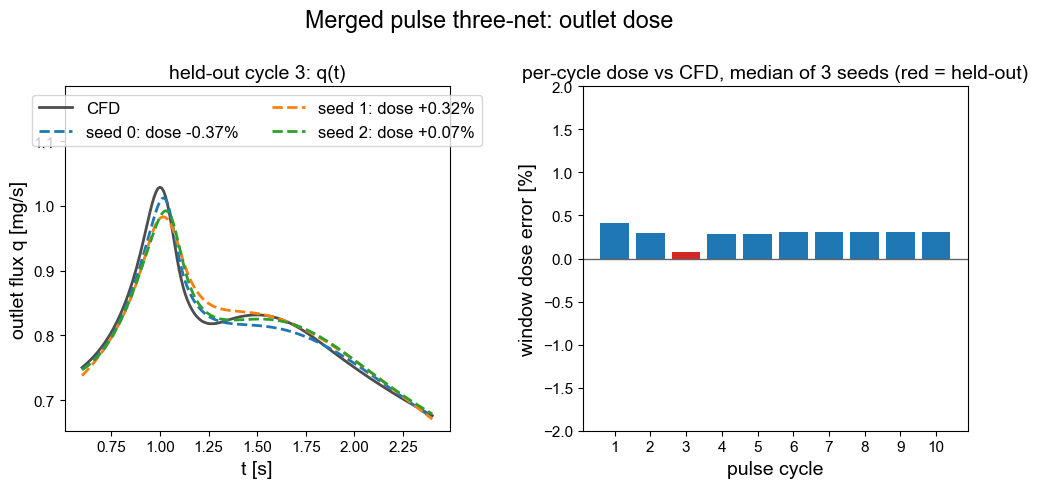

In [22]:
MS = json_util.load_json(RESULT / "merged_summary.json")
rows = [r for r in MS["rows"] if r["case"] in const.CFD_MERGED_CNET_CASES and "dose" in r]
if not rows:
    print("no dose evaluation for the merged c-nets yet")
else:
    d0 = rows[0]["dose"]
    ho_cycle = next(x["cycle"] for x in d0["rows"] if not x["trained"])
    i = list(DOSE_CFD["cycle"]).index(ho_cycle)
    t_cfd, q_cfd = np.asarray(DOSE_CFD["t"][i]), np.asarray(DOSE_CFD["q"][i])
    keep = (t_cfd >= const.CFD_T_WINDOW[0] - 1e-9) & (t_cfd <= const.CFD_T_WINDOW[1] + 1e-9)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    ax = axes[0]
    ax.plot(t_cfd[keep], q_cfd[keep], color="0.3", label="CFD")
    for r in rows:
        ho = next(x for x in r["dose"]["rows"] if not x["trained"])
        ax.plot(np.asarray(r["dose"]["t"]), np.asarray(ho["q"]), ls="--",
                label=f"seed {r['seed']}: dose {ho['rel_error']:+.2%}")
    ax.set_xlabel("t [s]")
    ax.set_ylabel("outlet flux q [mg/s]")
    ax.set_title(f"held-out cycle {ho_cycle}: q(t)")
    lo, up = ax.get_ylim()
    ax.set_ylim(lo, up + 0.35 * (up - lo))
    ax.legend(ncol=2, loc="upper center")
    ax = axes[1]
    xs = [x["cycle"] for x in d0["rows"]]
    med = [100 * MS["median"]["dose_by_cycle"][str(c)] for c in xs]
    ax.bar(xs, med, color=["tab:red" if c == ho_cycle else "tab:blue" for c in xs])
    ax.axhline(0, color="0.4", lw=1)
    ax.set_xticks(xs)
    ax.set_xlabel("pulse cycle")
    ax.set_ylabel("window dose error [%]")
    ax.set_title(f"per-cycle dose vs CFD, median of {len(rows)} seeds (red = held-out)")
    ax.set_ylim(-2, 2)
    fig.suptitle("Merged pulse three-net: outlet dose")
    fig.tight_layout()
    fig.savefig(FIGURE / "merged_dose.png")
    plt.show()

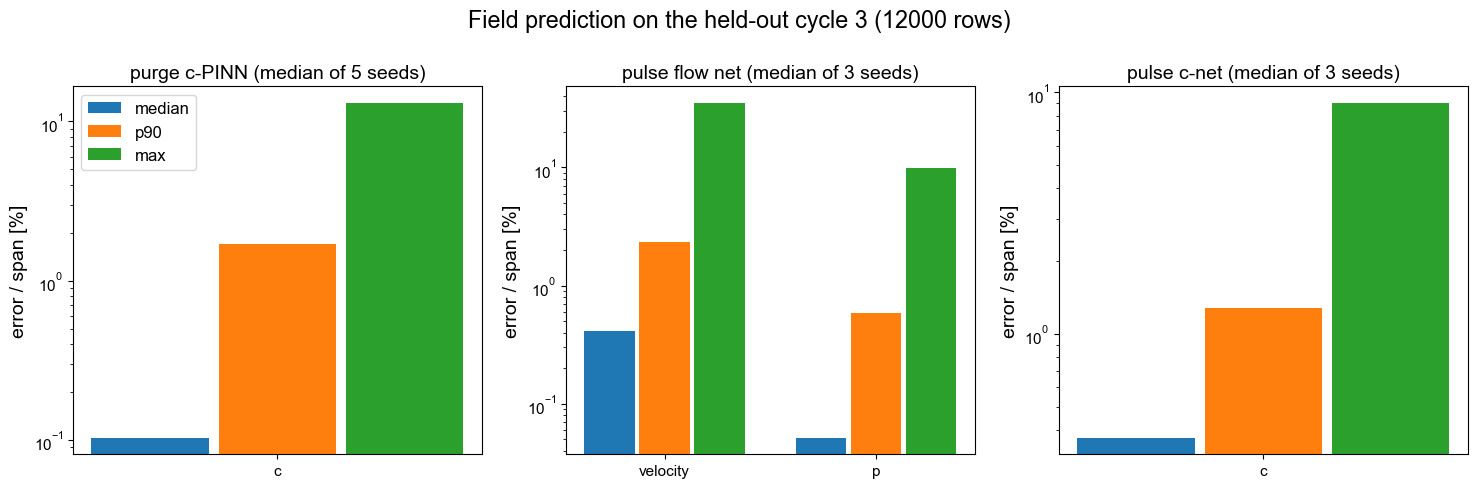

In [23]:
MS = json_util.load_json(RESULT / "merged_summary.json")
M = MS.get("median")
if M is None:
    print("no holdout evaluation yet")
else:
    PANELS = (("purge c-PINN", len(const.CFD_MERGED_PURGE_CASES), (("c", "purge_c"),)),
              ("pulse flow net", len(const.CFD_MERGED_FLOW_CASES), (("velocity", "pulse_velocity"), ("p", "pulse_p"))),
              ("pulse c-net", len(const.CFD_MERGED_CNET_CASES), (("c", "pulse_c"),)))
    fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 5), squeeze=False)
    for ax, (title, n_seed, keys) in zip(axes.ravel(), PANELS):
        x = np.arange(len(keys))
        for j, st in enumerate(("median", "p90", "max")):
            ax.bar(x + (j - 1) * 0.26, [100 * M[k][st] for _, k in keys], width=0.24, label=st)
        ax.set_yscale("log")
        ax.set_xticks(x)
        ax.set_xticklabels([label for label, _ in keys])
        ax.set_ylabel("error / span [%]")
        ax.set_title(f"{title} (median of {n_seed} seeds)")
    axes.ravel()[0].legend()
    fig.suptitle(f"Field prediction on the held-out cycle {const.CFD_MERGED_HOLDOUT} "
                 f"({MS['rows'][0]['holdout']['n']} rows)")
    fig.tight_layout()
    fig.savefig(FIGURE / "merged_field_error.png")
    plt.show()

## Inversion Summary

In [ ]:
if RERUN_MERGED:
    def seed_series(cases, key):
        out = []
        for name in cases:
            path = RESULT / f"{name}.json"
            if not path.exists():
                out.append(None)
                print(f"{name}: no record yet")
                continue
            rec = json_util.load_json(path)
            out.append((float(rec["estimate"]["params"][key]) / float(rec["true"][key]) - 1) * 100)
        return out


    D_SEEDS = (const.SEED,) + const.CFD_MERGED_PURGE_SEEDS
    MU_SEEDS = (const.SEED,) + const.CFD_MERGED_PULSE_SEEDS
    vals = seed_series(const.CFD_MERGED_PURGE_CASES, "D")
    mus = seed_series(const.CFD_MERGED_FLOW_CASES, "mu")
    for label, seeds, series in (("D  (merged purge)", D_SEEDS, vals), ("mu (merged flow) ", MU_SEEDS, mus)):
        print(f"\n{label} rel error [%] per seed (locked-in sdisc config)")
        print("  " + "".join(f"  seed {s}" for s in seeds))
        print("  " + "".join("     -- " if v is None else f"{v:+8.2f}" for v in series))
    if all(v is not None for v in vals + mus):
        arr = np.array(vals)
        stats = {"mean": float(arr.mean()), "sd": float(arr.std(ddof=1)), "sem": float(arr.std(ddof=1) / np.sqrt(arr.size))}
        print(f"\nD ensemble: mean {stats['mean']:+.2f}%, seed sd {stats['sd']:.2f} pp, sem {stats['sem']:.2f} pp")
        print(f"mu ensemble: median {np.median(mus):+.2f}%, spread {min(mus):+.2f} .. {max(mus):+.2f} pp "
              f"(merged-config figure on the mainline page; representation fixes falsified, see doc/decisions.md)")
        json_util.save_json(RESULT / "sdisc_seed_ensemble.json",
                            {"seeds": list(D_SEEDS), "D_rel": vals, "stats": stats,
                             "mu_seeds": list(MU_SEEDS), "mu_rel": mus, "mu_median": float(np.median(mus))})
        print(f"saved {RESULT / 'sdisc_seed_ensemble.json'}")


D  (merged purge) rel error [%] per seed (locked-in sdisc config)
    seed 0  seed 1  seed 2  seed 3  seed 4
     -1.27   -1.54   -1.78   -1.45   -1.44

mu (merged flow)  rel error [%] per seed (locked-in sdisc config)
    seed 0  seed 1  seed 2
    +18.57  +25.93  +23.49

D ensemble: mean -1.50%, seed sd 0.19 pp, sem 0.08 pp
mu ensemble: median +23.49%, spread +18.57 .. +25.93 pp (merged-config figure on the mainline page; representation fixes falsified, see doc/decisions.md)
saved result/cfd_invert_property/sdisc_seed_ensemble.json


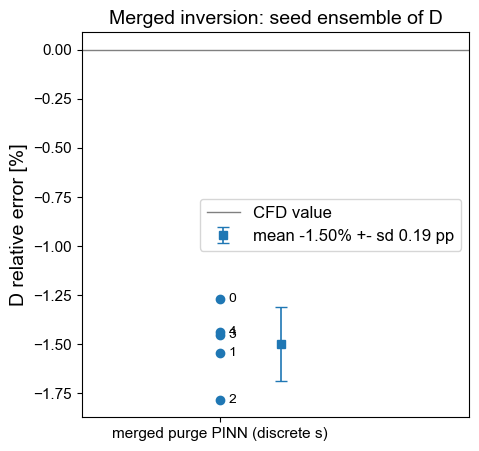

In [25]:
p_se = RESULT / "sdisc_seed_ensemble.json"
if not p_se.exists():
    print("no sdisc_seed_ensemble.json yet (records not all back)")
else:
    SE = json_util.load_json(p_se)
    fig, ax = plt.subplots()
    ax.axhline(0, color="gray", lw=1, label="CFD value")
    ax.scatter([0] * len(SE["D_rel"]), SE["D_rel"], color="C0", zorder=3)
    for s, v in zip(SE["seeds"], SE["D_rel"]):
        ax.annotate(str(s), (0, v), xytext=(6, 0), textcoords="offset points", fontsize=10, va="center")
    st = SE["stats"]
    ax.errorbar(0.22, st["mean"], yerr=st["sd"], fmt="s", color="C0", capsize=4, elinewidth=1.2, zorder=3,
                label=f"mean {st['mean']:+.2f}% +- sd {st['sd']:.2f} pp")
    ax.set_xlim(-0.5, 0.9)
    ax.set_xticks([0])
    ax.set_xticklabels(["merged purge PINN (discrete s)"])
    ax.set_ylabel("D relative error [%]")
    ax.set_title("Merged inversion: seed ensemble of D")
    ax.legend()
    fig.savefig(FIGURE / "sdisc_seed_ensemble.png")
    plt.show()

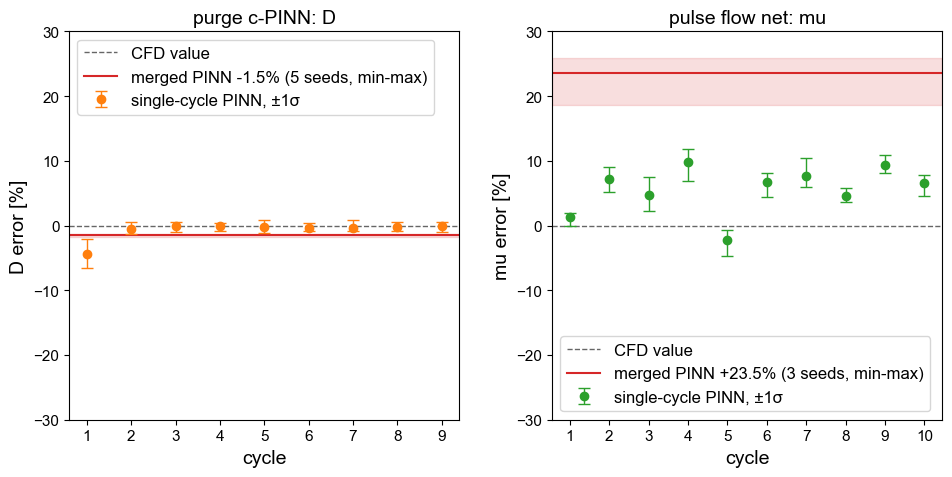

In [ ]:
ERROR_YLIM = (-30, 30)
summary = json_util.load_json(RESULT / "sweep_summary.json")
rows = [r for r in summary["rows"] if "param" in r]
p_se = RESULT / "sdisc_seed_ensemble.json"
if not rows or not p_se.exists():
    print("need both sweep_summary.json and sdisc_seed_ensemble.json: run the sweep and the merged summary first")
else:
    SE = json_util.load_json(p_se)
    MERGED = {"D": SE["D_rel"], "mu": SE["mu_rel"]}
    COLOR = {"purge": const.SPLIT_COLORS["valid"], "flow": const.SPLIT_COLORS["test"]}
    LABEL = {"purge": "purge c-PINN", "flow": "pulse flow net"}
    LEGEND_LOC = {"D": "upper left", "mu": "lower left"}

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, (net, key) in zip(axes, (("purge", "D"), ("flow", "mu"))):
        sub = sorted((r for r in rows if r["net"] == net), key=lambda r: r["index"])
        ax.axhline(0.0, color="0.4", ls="--", lw=1, label="CFD value")
        ax.set_xlabel("cycle")
        ax.set_ylabel(f"{key} error [%]")
        ax.set_title(f"{LABEL[net]}: {key}")
        if not sub:
            continue
        seeds = MERGED[key]
        ax.axhspan(min(seeds), max(seeds), color="C3", alpha=0.15)
        ax.axhline(float(np.median(seeds)), color="C3", lw=1.5,
                   label=f"merged PINN {np.median(seeds):+.1f}% ({len(seeds)} seeds, min-max)")
        good = [r for r in sub if not r["at_bound"]]
        ax.errorbar([r["index"] for r in good], [100.0 * r["rel_error"] for r in good],
                    yerr=[[r["lo_pp"] for r in good], [r["hi_pp"] for r in good]],
                    color=COLOR[net], marker="o", ls="none", capsize=4, elinewidth=1,
                    label="single-cycle PINN, ±1σ")
        ax.set_xticks([r["index"] for r in sub])
        ax.set_ylim(*ERROR_YLIM)
        ax.legend(loc=LEGEND_LOC[key])
        for r in sub:
            if r["at_bound"]:
                ax.plot(r["index"], ERROR_YLIM[1], color=COLOR[net], marker="^", ls="none", clip_on=False)
                print(f"off scale: {r['case']} {100.0 * r['rel_error']:+.0f}% ({key} ran to the search bound)")
    fig.tight_layout()
    fig.savefig(FIGURE / "sweep_vs_merged_params.png")
    plt.show()

In [ ]:
if RERUN_MERGED:
    MERGED_NETS = (("purge", const.CFD_MERGED_PURGE_CASES, "purge_all", "purge", CNET_FIELDS),
                   ("flow", const.CFD_MERGED_FLOW_CASES, "pulse_all_flow", "pulse", FLOW_FIELDS),
                   ("cnet", const.CFD_MERGED_CNET_CASES, "pulse_all_c", "pulse", CNET_FIELDS))


    def cycle_block(seg_key, kind, cycle, single_key):
        seg = SEGMENT[f"{kind}_holdout"] if cycle == const.CFD_MERGED_HOLDOUT else SEGMENT[seg_key]
        ds = seg["dataset"]
        block = (np.arange(ds["X"].shape[0]) if cycle == const.CFD_MERGED_HOLDOUT
                 else np.flatnonzero(ds["cycle"] == cycle))
        single = SEGMENT[single_key]["dataset"]
        assert np.array_equal(ds["node"][block], single["node"]), f"cycle {cycle}: merged rows differ from the single case"
        assert np.array_equal(ds["time_index"][block], single["time_index"])
        rows = block[pinn_training.PINNTraining.split_index(block.size, const.SPLIT_PATTERN, ds["node"][block])[2]]
        return ds, rows


    def field_errors(comp, pred, fields):
        if "u" in fields:
            c = np.column_stack([comp[f] for f in ("u", "v", "w")])
            p = np.column_stack([pred[f] for f in ("u", "v", "w")])
            return {"u": np.linalg.norm(p - c, axis=1) / np.ptp(np.linalg.norm(c, axis=1)),
                    "p": np.abs(pred["p"] - comp["p"]) / np.ptp(comp["p"])}
        return {"c": np.abs(pred["c"] - comp["c"]) / np.ptp(comp["c"])}


    BOX_KEYS = ("whislo", "q1", "med", "q3", "whishi")
    merged_rows = []
    for net, cases, seg_key, kind, fields in MERGED_NETS:
        cycles = sorted(SEGMENT[seg_key]["cycles"] + [const.CFD_MERGED_HOLDOUT])
        models = []
        for name in cases:
            path = RESULT / f"{name}.pt"
            if not path.exists():
                print(f"{name}: no checkpoint yet, skipped")
                continue
            models.append((name, pinn_training.PINNTraining.load_checkpoint(path, feature=FEATURE)[0]))
        if not models:
            continue
        for cycle in cycles:
            tag = cycle_tag(cycle)
            ds, rows = cycle_block(seg_key, kind, cycle, f"purge{tag}" if kind == "purge" else f"pulse{tag}_flow")
            comp = {f: np.asarray(ds[f])[rows] for f in fields}
            per_seed = {}
            for name, model in models:
                pred = pinn_training.PINNTraining.evaluation(model, ds["X"][rows], fields)
                for field, err in field_errors(comp, pred, fields).items():
                    per_seed.setdefault(field, []).append(np.percentile(100.0 * err, [5, 25, 50, 75, 95]))
            for field, stats in per_seed.items():
                med = np.median(np.array(stats), axis=0)
                merged_rows.append({"net": net, "index": cycle, "field": field, "n": int(rows.size),
                                    "n_seed": len(models), "trained": cycle != const.CFD_MERGED_HOLDOUT,
                                    "box": {k: float(v) for k, v in zip(BOX_KEYS, med)}})
    json_util.save_json(RESULT / "merged_field_error.json", {"rows": merged_rows, "whiskers": [5, 95],
                                                             "holdout": const.CFD_MERGED_HOLDOUT})

    SINGLE_BOX = {(r["net"], r["index"], r["field"]): r["box"]
                  for r in json_util.load_json(RESULT / "sweep_field_error.json")["rows"]}
    print(f"{len(merged_rows)} cycle-field rows from the merged nets (test split of each single-cycle case, "
          f"error / span in %; merged numbers are the seed-ensemble median)")
    print(f"\n{'net':<7}{'cycle':>6}{'field':>7}{'n':>7}{'merged med':>12}{'single med':>12}"
          f"{'merged p95':>12}{'single p95':>12}")
    for r in merged_rows:
        single = SINGLE_BOX.get((r["net"], r["index"], r["field"]))
        mark = "" if r["trained"] else "   <- not in merged training"
        print(f"{r['net']:<7}{r['index']:>6}{r['field']:>7}{r['n']:>7}{r['box']['med']:>12.3f}"
              + (f"{single['med']:>12.3f}" if single else f"{'--':>12}")
              + f"{r['box']['whishi']:>12.3f}"
              + (f"{single['whishi']:>12.3f}" if single else f"{'--':>12}") + mark)

39 cycle-field rows from the merged nets (test split of each single-cycle case, error / span in %; merged numbers are the seed-ensemble median)

net     cycle  field      n  merged med  single med  merged p95  single p95
purge       1      c   1189       0.161       0.121       4.135       4.662
purge       2      c   1189       0.113       0.095       3.862       4.534
purge       3      c   1189       0.106       0.123       3.797       4.293   <- not in merged training
purge       4      c   1189       0.114       0.107       3.729       4.071
purge       5      c   1189       0.111       0.105       3.684       4.105
purge       6      c   1189       0.112       0.103       3.683       4.145
purge       7      c   1189       0.112       0.097       3.683       3.802
purge       8      c   1189       0.112       0.105       3.683       4.154
purge       9      c   1189       0.112       0.121       3.683       4.108
flow        1      u   1189       0.475       0.687       3.968    

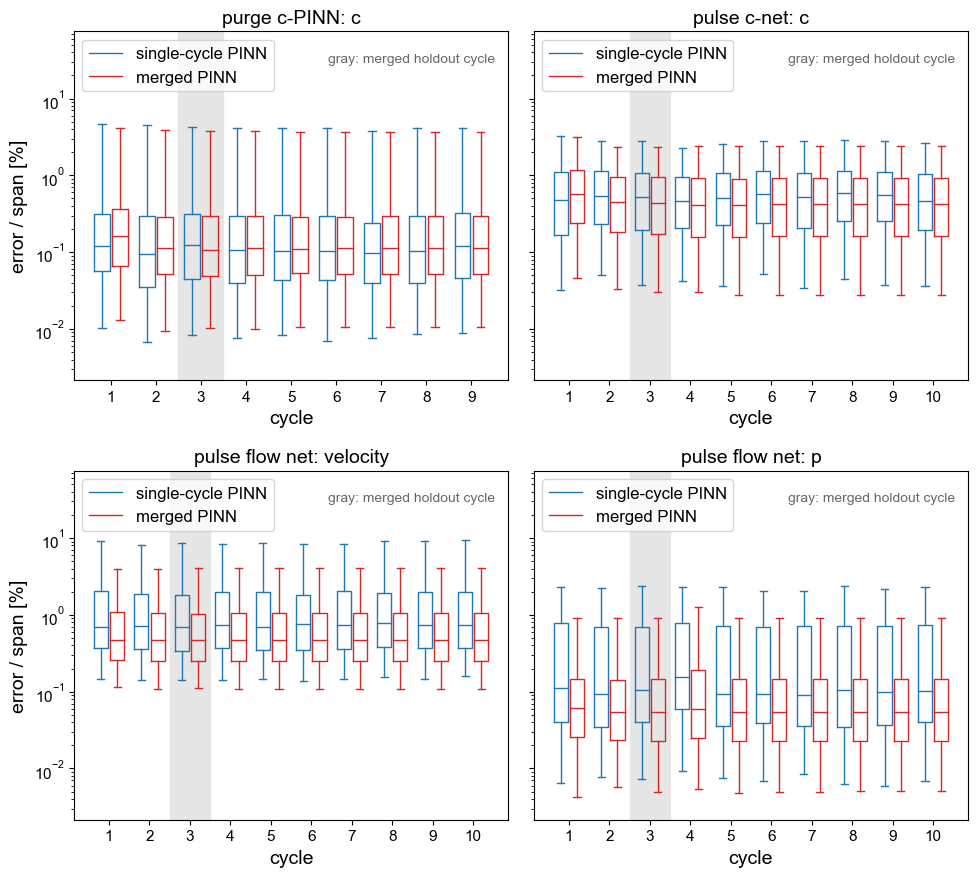

In [ ]:
FE = json_util.load_json(RESULT / "sweep_field_error.json")
ME = json_util.load_json(RESULT / "merged_field_error.json")
BOX = {"single": {(r["net"], r["index"], r["field"]): r["box"] for r in FE["rows"]},
       "merged": {(r["net"], r["index"], r["field"]): r["box"] for r in ME["rows"]}}
PANELS = (("purge", "c", "purge c-PINN: c"), ("cnet", "c", "pulse c-net: c"),
          ("flow", "u", "pulse flow net: velocity"), ("flow", "p", "pulse flow net: p"))
MODEL = {"single": ("C0", "single-cycle PINN"), "merged": ("C3", "merged PINN")}

fig, axes = plt.subplots(2, 2, figsize=(10, 9), sharey=True)
for ax, (net, field, title) in zip(axes.ravel(), PANELS):
    idx = sorted({k[1] for m in BOX for k in BOX[m] if k[0] == net and k[2] == field})
    ax.axvspan(ME["holdout"] - 0.5, ME["holdout"] + 0.5, color="0.9", zorder=0)
    for j, model in enumerate(MODEL):
        color, label = MODEL[model]
        keys = [i for i in idx if (net, i, field) in BOX[model]]
        if not keys:
            continue
        props = {"color": color}
        art = ax.bxp([BOX[model][(net, i, field)] for i in keys], positions=[i + (j - 0.5) * 0.4 for i in keys],
                     widths=0.35, showfliers=False, manage_ticks=False, boxprops=props, whiskerprops=props,
                     capprops=props, medianprops=props)
        art["boxes"][0].set_label(label)
    ax.set_yscale("log")
    ax.set_xticks(idx)
    ax.set_xlabel("cycle")
    ax.set_title(title)
    ax.legend(loc="upper left")
    ax.text(0.97, 0.94, "gray: merged holdout cycle", transform=ax.transAxes, ha="right", va="top",
            fontsize=10, color="0.4")
for ax in axes[:, 0]:
    ax.set_ylabel("error / span [%]")
whis = [v for model in BOX for box in BOX[model].values() for v in (box["whislo"], box["whishi"])]
axes[0, 0].set_ylim(min(whis) / 2.0, max(whis) * 8.0)
fig.tight_layout()
fig.savefig(FIGURE / "single_vs_merged_field_error.png")
plt.show()

### Summary

# Standard Figures

In [26]:
RERUN_STANDARD_FIGURES = False
if RERUN_STANDARD_FIGURES:
    PLOT_EVERY_CASE = True
    BACKEND = plt.get_backend()
    plt.switch_backend("agg")
    try:
        for name in (const.CFD_CASES if PLOT_EVERY_CASE else ()):
            path = RESULT / f"{name}.json"
            if not path.exists():
                continue
            rec = json_util.load_json(path)
            fields = tuple(rec["config"]["fields"])
            best = pinn_training.PINNTraining.best_axis(rec["best"])
            pinn_training.PINNTraining.plot_loss(rec["history"], FIGURE / f"{name}_loss.png",
                                                 title=f"Case {name}: loss history", best_epoch=best)
            pinn_training.PINNTraining.plot_diag(rec["test"], fields, (1, len(fields)), FIGURE / f"{name}_diag.png",
                                                 title=f"Case {name}: test diagonal (n = {rec['split']['test']})",
                                                 units=diag_units(rec))
            n_colloc = rec["n_colloc"]
            pinn_training.PINNTraining.plot_residual(
                rec["residual"], FIGURE / f"{name}_residual.png",
                title=f"Case {name}: collocation residual "
                      f"(train/valid/test = {n_colloc['train']}/{n_colloc['valid']}/{n_colloc['test']})")
            if rec["params"]:
                pinn_training.PINNTraining.plot_params(history_dim(rec), params=rec["params_dim"], true=rec["true_dim"],
                                                       estimate=rec["estimate_dim"], path=FIGURE / f"{name}_params.png",
                                                       best_epoch=best, title=None)
            plt.close("all")
            print(f"[{name}] standard figures written to {FIGURE}")
    finally:
        plt.switch_backend(BACKEND)

[purge_D] standard figures written to result/cfd_invert_property/figure


[purge2_D] standard figures written to result/cfd_invert_property/figure


[purge3_D] standard figures written to result/cfd_invert_property/figure


[purge4_D] standard figures written to result/cfd_invert_property/figure


[purge5_D] standard figures written to result/cfd_invert_property/figure


[purge6_D] standard figures written to result/cfd_invert_property/figure


... (30 outputs left out)

[purge_all_D_sdisc_s1] standard figures written to result/cfd_invert_property/figure


[purge_all_D_sdisc_s2] standard figures written to result/cfd_invert_property/figure


[purge_all_D_sdisc_s3] standard figures written to result/cfd_invert_property/figure


[purge_all_D_sdisc_s4] standard figures written to result/cfd_invert_property/figure
